# COMP6008 Smart Irrigation RL — Shared Group Notebook

**Group Member:** Malaika Noor.  
**Location:** Kyabram, Victoria  
**Algorithms:** DDPG, TD3 and SAC  
**Status:** Shared environment and experiment framework complete. SAC implementation, tuning, final evaluation, reward sensitivity and robustness experiments completed. DDPG and TD3 integration and the final cross-agent comparison are tracked separately.

This notebook is the common starting point for all three agents. It covers the project objectives, fixed MDP, validated simulator, reproducibility controls, benchmarks, tuning rules, evaluation metrics, robustness tests and reporting structure. Each member should copy it and edit only their assigned agent section until integration.


## 0. Project-objective map

| Project objective | Where it is addressed in this notebook |
|---|---|
| 1. Explain the RL concepts and why they apply | Scientific rationale, return, exploration and actor–critic discussion below |
| 2. Formulate the environment and examine MDP assumptions | Fixed MDP, 18-value observation, transition equations, reward, partial-observability limitations and Gymnasium implementation |
| 3. Implement and tune three suitable agents | Separate DDPG, TD3 and SAC work areas, shared interface, fixed grids and validation-only selection function |
| 4. Evaluate performance, stability and generalisation | Physical metrics, learning curves, seed summaries, held-out seasons, stability/sample-efficiency functions and robustness suite |
| 5. Identify problems and explain their causes | Physics/information-timing tests, terminal checks and a structured failure log |
| 6. Document and communicate findings | Evidence–reasoning–limitations prompts, references, result tables and interpretation checklist |
| 7. Plan and share the work fairly | Agent ownership plus environment, infrastructure and evaluation responsibilities, with integration review |

The detailed scientific justification remains in [`PROJECT_OBJECTIVES.md`](../docs/PROJECT_OBJECTIVES.md). The numerical source of truth is [`FIXED_EXPERIMENT_SETTINGS.md`](../docs/FIXED_EXPERIMENT_SETTINGS.md).


## 1. Group allocation and parallel workflow

Agent owners are confirmed below; agree on shared responsibilities and review partners before making the remaining agent copies. Every member owns one agent and one shared responsibility.

| Responsibility | Group member | Branch/notebook | Review partner | Status |
|---|---|---|---|---|
| DDPG implementation, pseudocode and analysis | Raina Shah | `01_ddpg.ipynb` | TODO | Not started |
| TD3 implementation, pseudocode and analysis | Arnav Dangmali | `02_td3.ipynb` | TODO | Not started |
| SAC implementation, pseudocode and analysis | Malaika Noor | `03_sac.ipynb` | Completed| Implementation, tuning, five-seed evaluation, reward sensitivity and robustness completed |
| Environment integration and validation | TODO | Shared | TODO | Framework ready |
| Training/data infrastructure | TODO | Shared | TODO | Framework ready |
| Evaluation, plots and final integration | TODO | Shared | TODO | Framework ready |

Rules:

1. Do not independently alter the environment, data splits, reward or shared budgets in an agent notebook.
2. Record proposed changes and obtain group agreement before final testing.
3. Merge early using short smoke runs; do not wait for full training.
4. Reassess workload after the first working agent versions and redistribute shared work if necessary.
5. Every member must be able to explain the environment and all three algorithms.
6. Each member will later propose one improvement tied to an observed limitation and one separate future direction with supporting literature.

Save each agent’s results, checkpoints and visualisations in its own directory: `outputs/ddpg/`, `outputs/td3/` or `outputs/sac/`. Use `agent_output_dir("td3")` or `agent_output_dir("sac")` in the new agent notebooks.


## 2. Scientific rationale and practical-code provenance

Irrigation is sequential because today's irrigation changes tomorrow's soil-water state. The agent should therefore maximise a seasonal return rather than minimise only today's water use:

$$G_t=\sum_{k=0}^{T-t-1}\gamma^kR_{t+k+1}.$$

The policy selects irrigation, while the critic/value function estimates longer-term consequences [1, Secs. 3.3–3.5]. Exploration occurs only in the simulator; random actions are not proposed for a real field. A threshold controller is retained because the project must test whether RL adds value rather than assume that it does.

The continuous action is the reason for selecting actor–critic methods:

| Agent | Scientific reason for inclusion |
|---|---|
| DDPG | Deterministic off-policy actor–critic baseline for continuous control, with replay and target networks [4] |
| TD3 | Tests whether twin critics, delayed policy updates and target smoothing improve on DDPG's stability [5] |
| SAC | Tests a stochastic maximum-entropy approach to exploration under changing weather [6] |

These papers justify testing the algorithms; they do not predict which one will perform best here. That conclusion must come from repeated held-out experiments [7].

### Relationship to the unit practicals

This notebook follows [`PRACTICAL_CODE_REUSE.md`](../docs/PRACTICAL_CODE_REUSE.md). We adapt:

- Practical 1's Gymnasium interaction and `terminated`/`truncated` handling;
- Practicals 4–5's TD-target and terminal-mask reasoning;
- Practical 8's replay buffer, minibatches, target networks and training-loop organisation; and
- Practical 9's actor/critic separation, MLP structure, Adam optimisation and evaluation pattern.

We do **not** copy discrete-action logic unchanged. DQN's `argmax`, action-index `gather()` and one-Q-output-per-action design are unsuitable. Practical 9's categorical policy is also unsuitable. The continuous policies, action-conditioned critics and DDPG/TD3/SAC losses must be implemented from the original papers.

Each agent section must identify: the practical used as a structural starting point, what was retained, what changed for continuous control, the matching pseudocode step and the original paper supporting the final update.


## 3. Setup

Run the installation cell once per Colab session. The final run should record the resolved package versions and hardware below.


In [1]:
%pip install -q "gymnasium>=1.0,<2" "numpy>=1.22" "torch>=2.0" "pandas>=2.0" "matplotlib>=3.7"


[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from __future__ import annotations

import hashlib
import json
import platform
import random
import time
import warnings
from collections import deque
from dataclasses import asdict, dataclass, replace
from datetime import date, timedelta
from itertools import product
from pathlib import Path
from typing import Any
from zipfile import ZipFile

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from gymnasium import spaces
from gymnasium.utils.env_checker import check_env

RUNTIME = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "gymnasium": gym.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "torch": torch.__version__,
    "device": "cuda" if torch.cuda.is_available() else "cpu",
}
RUNTIME


{'python': '3.13.2',
 'platform': 'macOS-26.3.1-arm64-arm-64bit-Mach-O',
 'gymnasium': '1.4.0',
 'numpy': '2.5.3',
 'pandas': '3.0.6',
 'torch': '2.14.1',
 'device': 'cpu'}

## 4. Data, provenance and scope

The environment uses Kyabram SILO rainfall and FAO-56 reference evapotranspiration. Soil capacity comes from the audited CSIRO Soil and Landscape Grid extraction. SILO source flags remain in the archive even though the controller uses only rainfall and ETo. Interpolated values must not be described as station observations [8].

The climate forcing is historical; soil water, irrigation, drainage and crop response are simulated. The coordinate represents a virtual field, not a verified commercial paddock. The simulator is suitable for a comparative RL study, not a field-ready irrigation recommendation.

The required archive is [`data/Irrigation_Data_Audit.zip`](../data/Irrigation_Data_Audit.zip). If Colab does not mount repository files, upload that ZIP through the Files panel.


In [3]:
DATA_CANDIDATES = [
    Path("../data/Irrigation_Data_Audit.zip"),  # when launched from notebooks/
    Path("data/Irrigation_Data_Audit.zip"),    # when working directory is repository root
    Path("Irrigation_Data_Audit.zip"),
    Path("/content/Irrigation_Data_Audit.zip"),
    Path("../irrigation_audit/kyabram_080091_daily.json"),
    Path("irrigation_audit/kyabram_080091_daily.json"),
]
DATA_PATH = next((path for path in DATA_CANDIDATES if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Upload Irrigation_Data_Audit.zip and rerun this cell. "
        "The expected Colab path is /content/Irrigation_Data_Audit.zip."
    )

DATA_SHA256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
print("Using:", DATA_PATH.resolve())
print("SHA-256:", DATA_SHA256)

# Resolve outputs consistently from repository root, notebooks/, or standalone Colab.
PROJECT_ROOT = next((p.resolve() for p in (Path.cwd(), Path.cwd().parent)
                     if (p / "notebooks").is_dir()), Path.cwd())
OUTPUT_ROOT = PROJECT_ROOT / "outputs"
AGENT_OUTPUT_DIRS = {name: OUTPUT_ROOT / name for name in ("ddpg", "td3", "sac")}

def agent_output_dir(agent_name):
    if agent_name not in AGENT_OUTPUT_DIRS:
        raise ValueError("Choose ddpg, td3, or sac")
    directory = AGENT_OUTPUT_DIRS[agent_name]
    directory.mkdir(parents=True, exist_ok=True)
    return directory


Using: /Users/zainumair12gmail.com/Desktop/comp6008-smart-irrigation-rl/data/Irrigation_Data_Audit.zip
SHA-256: ce6d02d87ea7cb980f61f78bdd288d6ad035744042dae1eb3e43f0facaa54e08


## 5. Frozen shared settings and declared experimental plans

These settings must be identical across DDPG, TD3 and SAC. Agent-specific selected values remain `None` until validation-only tuning is complete. Test seasons must not influence a setting, checkpoint or reward choice.


In [4]:
TRAIN_YEARS = tuple(range(2005, 2017))
VALIDATION_YEARS = tuple(range(2017, 2021))
TEST_YEARS = tuple(range(2021, 2025))
SEASON_SPLITS = {
    "train": TRAIN_YEARS,
    "validation": VALIDATION_YEARS,
    "test": TEST_YEARS,
    "all": TRAIN_YEARS + VALIDATION_YEARS + TEST_YEARS,
}


@dataclass(frozen=True)
class EnvironmentConfig:
    capacity_mm: float = 111.33333333333334
    initial_storage_fraction: float = 0.80
    max_irrigation_mm: float = 20.0
    irrigation_efficiency: float = 0.85
    season_length_days: int = 150
    planting_month: int = 11
    planting_day: int = 1
    planting_day_offset: int = 0
    kc_multiplier: float = 1.0
    irrigation_weight: float = 1.0
    shortage_weight: float = 10.0
    drainage_weight: float = 1.0
    rainfall_scale_mm: float = 20.0
    eto_scale_mm: float = 10.0
    history_days: int = 7

    def __post_init__(self):
        if self.capacity_mm <= 0 or self.max_irrigation_mm <= 0:
            raise ValueError("Storage capacity and irrigation limit must be positive")
        if not 0 < self.initial_storage_fraction <= 1:
            raise ValueError("Initial storage fraction must be in (0, 1]")
        if not 0 < self.irrigation_efficiency <= 1:
            raise ValueError("Irrigation efficiency must be in (0, 1]")
        if self.season_length_days != 150 or self.history_days != 7:
            raise ValueError("The fixed experiment uses 150 days and seven history days")
        if not 0 < self.kc_multiplier <= 1.1:
            raise ValueError("Kc multiplier must be in (0, 1.1]")
        if min(self.irrigation_weight, self.shortage_weight, self.drainage_weight) < 0:
            raise ValueError("Reward weights must be non-negative")


ENV_CONFIG = EnvironmentConfig()

SHARED_TRAINING = {
    "gamma": 0.995,
    "tau": 0.005,
    "replay_capacity": 100_000,
    "batch_size": 128,
    "random_exploration_steps": 1_500,
    "hidden_sizes": (128, 128),
    "optimiser": "Adam",
    "optimiser_betas": (0.9, 0.999),
    "optimiser_epsilon": 1e-8,
    "updates_per_environment_step": 1,
    "final_training_steps": 100_000,
    "tuning_steps": 30_000,
    "evaluation_interval": 5_000,
    "final_checkpoint": 100_000,
    "final_seeds": (11, 22, 33, 44, 55),
    "tuning_seeds": (101, 202),
}

AGENT_TUNING_GRIDS = {
    "ddpg": [
        {"learning_rate": lr, "exploration_std": std}
        for lr, std in product((1e-4, 3e-4), (0.1, 0.2))
    ],
    "td3": [
        {"learning_rate": lr, "exploration_std": std}
        for lr, std in product((1e-4, 3e-4), (0.1, 0.2))
    ],
    "sac": [
        {"learning_rate": lr, "alpha": alpha}
        for lr, alpha in product((1e-4, 3e-4), (0.1, 0.2))
    ],
}

AGENT_SETTINGS = {
    "ddpg": {"owner": "Raina Shah", "selected_learning_rate": None, "selected_exploration_std": None},
    "td3": {
        "owner": "Arnav Dangmali", "selected_learning_rate": None, "selected_exploration_std": None,
        "policy_delay": 2, "target_smoothing_std": 0.2, "target_noise_clip": 0.5,
    },
    "sac": {
        "owner": "Malaika Noor", "selected_learning_rate": None, "selected_alpha": None,
        "formulation": "Haarnoja et al. (2018), separate value network, fixed alpha",
        "log_std_bounds": None,  # document before SAC training
    },
}

ROBUSTNESS_CONFIGS = {
    "capacity_0.8": replace(ENV_CONFIG, capacity_mm=0.8 * ENV_CONFIG.capacity_mm),
    "capacity_1.2": replace(ENV_CONFIG, capacity_mm=1.2 * ENV_CONFIG.capacity_mm),
    "root_zone_0.6m": replace(ENV_CONFIG, capacity_mm=72.0),
    "efficiency_0.75": replace(ENV_CONFIG, irrigation_efficiency=0.75),
    "efficiency_0.95": replace(ENV_CONFIG, irrigation_efficiency=0.95),
    "planting_minus_14d": replace(ENV_CONFIG, planting_day_offset=-14),
    "planting_plus_14d": replace(ENV_CONFIG, planting_day_offset=14),
    "kc_0.9": replace(ENV_CONFIG, kc_multiplier=0.9),
    "kc_1.1": replace(ENV_CONFIG, kc_multiplier=1.1),
}

REWARD_SENSITIVITY_CONFIGS = {
    "shortage_weight_5": replace(ENV_CONFIG, shortage_weight=5.0),
    "shortage_weight_20": replace(ENV_CONFIG, shortage_weight=20.0),
}


def make_season_schedule(seed, total_steps):
    # Shared episode schedule; independent from network and exploration RNGs.
    episode_count = int(np.ceil(total_steps / ENV_CONFIG.season_length_days)) + 1
    rng = np.random.default_rng(seed)
    return tuple(int(year) for year in rng.choice(TRAIN_YEARS, size=episode_count, replace=True))


def configuration_fingerprint(config=ENV_CONFIG):
    payload = {"environment": asdict(config), "training": SHARED_TRAINING, "data_sha256": DATA_SHA256}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()


EXPERIMENT_TOTALS = {
    "tuning": 3 * 4 * 2 * 30_000,
    "five_seed_final_training": 3 * 5 * 100_000,
    "reward_sensitivity": 3 * 2 * 2 * 30_000,
}
EXPERIMENT_TOTALS["total_learning_interactions"] = sum(EXPERIMENT_TOTALS.values())

print("Configuration fingerprint:", configuration_fingerprint())
print("Planned learning interactions:", EXPERIMENT_TOTALS)


Configuration fingerprint: 7fc3978e1036c4192871625454e78e071d739b3e01762ebbe99108120866f282
Planned learning interactions: {'tuning': 720000, 'five_seed_final_training': 1500000, 'reward_sensitivity': 360000, 'total_learning_interactions': 2580000}


## 6. MDP, observation and simulator equations

At day $t$, the agent receives $O_t$, selects irrigation $I_t$, and the environment returns $R_{t+1}$ and $O_{t+1}$. The hidden simulator state includes storage, day, selected historical season and weather history. The policy does not receive the season identifier or future weather. Therefore, the internal simulator is Markov, but the agent faces a **partially observable** control problem; seven past weather days are an approximation to a sufficient observation [1, Sec. 3.1].

We model grain maize planted on 1 November for 150 days. The single crop-coefficient schedule is 0.30 for days 0–29, increases to 1.20 over days 30–69, remains 1.20 for days 70–119 and decreases to 0.35 over days 120–149. This transfers the FAO-56 example calendar to a southern-hemisphere summer as an explicit assumption rather than a measured Kyabram cultivar [2,10].

The nominal 1.0 m reservoir capacity is 111.3333 mm, calculated from the audited CSIRO AWC layers: 6.25 mm (0–5 cm), 13.00 mm (5–15 cm), 18.25 mm (15–30 cm), 34.50 mm (30–60 cm) and 39.3333 mm (60–100 cm). These are service-generated digital-soil estimates, not field measurements [11,12]. Each episode begins at $0.8C$. The separate 0.6 m sensitivity case uses the first four layers, giving 72.0 mm.

The 18 values are: $A_t/C$, $t/150$, $K_{c,t}/1.2$, $I_{t-1}/20$, seven previous rainfall values divided by 20 and seven previous ETo values divided by 10. The current day's weather is unknown when the action is chosen.

The policy action $u_t\in[-1,1]$ maps to $I_t=10(u_t+1)$ mm. The fixed daily calculation is:

$$ET_{c,t}=K_{c,t}ET_{o,t},\quad p_t=\operatorname{clip}[0.55+0.04(5-ET_{c,t}),0.1,0.8],\quad A_{\min,t}=(1-p_t)C,$$

$$B_t=A_t+P_t+\eta I_t,\quad D_t=\max(0,B_t-C),\quad H_t=B_t-D_t,$$

$$K_{s,t}=\min(1,H_t/A_{\min,t}),\quad ET_{a,t}=\min(H_t,K_{s,t}ET_{c,t}),\quad A_{t+1}=H_t-ET_{a,t}.$$

The mass balance must satisfy $A_{t+1}=A_t+P_t+\eta I_t-D_t-ET_{a,t}$. The model assumes zero runoff and capillary rise, immediate bucket-overflow drainage and no explicit yield or waterlogging damage. These are simplifying assumptions, not measured Kyabram field behaviour [2,3,9,10].

The environmental reward is:

$$R_{t+1}=-\left[\frac{I_t}{20}+10\max\left(0,\frac{A_{\min,t}-A_{t+1}}{A_{\min,t}}\right)+\frac{D_t}{20}\right].$$

The weights $(1,10,1)$ are declared project preferences, not published crop-response parameters. Reward sensitivity therefore repeats short runs with shortage weights 5 and 20. The shared discount is $\gamma=0.995$; SAC's entropy term is excluded from the environmental return used for comparison.


## 7. Shared Gymnasium environment

The action is selected before the current day's rainfall and ETo are revealed. The next observation contains only completed weather history. Diagnostic `info` is used for evaluation and debugging but is never an actor or critic input.


In [5]:
KYABRAM_MEMBER = 'irrigation_audit/kyabram_080091_daily.json'

class KyabramIrrigationEnv(gym.Env):
    metadata = {'render_modes': ['rgb_array'], 'render_fps': 8}

    def __init__(self, climate_path=DATA_PATH, split='train', config=ENV_CONFIG, render_mode=None):
        super().__init__()
        if render_mode not in (None, "rgb_array"):
            raise ValueError("Supported render_mode: rgb_array or None")
        self.render_mode = render_mode
        if split not in SEASON_SPLITS:
            raise ValueError(f'Unknown split: {split}')
        self.config = config
        self.split = split
        self.allowed_years = SEASON_SPLITS[split]
        records = self._load_records(Path(climate_path))
        self._weather, self._dates = self._build_seasons(records)
        self.action_space = spaces.Box(-1.0, 1.0, shape=(1,), dtype=np.float32)
        self.observation_space = spaces.Box(
            low=np.zeros(18, dtype=np.float32),
            high=np.array([1.0, 1.0, 1.1, 1.0] + [np.inf] * 14, dtype=np.float32),
            dtype=np.float32,
        )
        self.season_year = None
        self.day = config.season_length_days
        self.storage_mm = 0.0
        self.previous_irrigation_mm = 0.0
        self._terminated = True

    @staticmethod
    def _load_records(path):
        if path.is_dir():
            path = path / 'kyabram_080091_daily.json'
        if path.suffix.lower() == '.zip':
            with ZipFile(path) as archive:
                payload = json.loads(archive.read(KYABRAM_MEMBER))
        else:
            payload = json.loads(path.read_text())
        records = {}
        for index, row in enumerate(payload):
            try:
                current_date = date.fromisoformat(row['date'])
                rain = float(row['rain_mm'])
                eto = float(row['eto_mm'])
            except (KeyError, TypeError, ValueError) as exc:
                raise ValueError(f'Malformed climate row {index}') from exc
            if current_date in records or not np.isfinite([rain, eto]).all():
                raise ValueError(f'Invalid climate input on {current_date}')
            if rain < 0 or eto < 0:
                raise ValueError(f'Negative climate input on {current_date}')
            records[current_date] = (rain, eto)
        return records

    def _build_seasons(self, records):
        weather, dates = {}, {}
        block_length = self.config.history_days + self.config.season_length_days
        for year in SEASON_SPLITS['all']:
            planting = date(year, self.config.planting_month, self.config.planting_day)
            planting += timedelta(days=self.config.planting_day_offset)
            start = planting - timedelta(days=self.config.history_days)
            block_dates = tuple(start + timedelta(days=i) for i in range(block_length))
            missing = [day for day in block_dates if day not in records]
            if missing:
                raise ValueError(f'Season {year} is missing {missing[0]}')
            weather[year] = np.asarray([records[day] for day in block_dates], dtype=np.float64)
            dates[year] = block_dates
        return weather, dates

    def _kc(self, day):
        if day >= self.config.season_length_days:
            return 0.0
        if day < 30:
            base = 0.30
        elif day < 70:
            base = 0.30 + 0.90 * (day - 29) / 40
        elif day < 120:
            base = 1.20
        else:
            base = 1.20 - 0.85 * (day - 119) / 30
        return self.config.kc_multiplier * base

    def _observation(self):
        history = self._weather[self.season_year][self.day:self.day + 7][::-1]
        observation = np.concatenate([
            np.array([
                self.storage_mm / self.config.capacity_mm,
                self.day / self.config.season_length_days,
                self._kc(self.day) / 1.2,
                self.previous_irrigation_mm / self.config.max_irrigation_mm,
            ]),
            history[:, 0] / self.config.rainfall_scale_mm,
            history[:, 1] / self.config.eto_scale_mm,
        ]).astype(np.float32)
        if not np.isfinite(observation).all() or not self.observation_space.contains(observation):
            raise RuntimeError('Invalid observation produced')
        return observation

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        options = {} if options is None else dict(options)
        unknown_options = set(options) - {'season_year'}
        if unknown_options:
            raise ValueError(f'Unknown reset options: {sorted(unknown_options)}')
        requested_year = options.get('season_year')
        if requested_year is None:
            self.season_year = self.allowed_years[int(self.np_random.integers(len(self.allowed_years)))]
        elif int(requested_year) in self.allowed_years:
            self.season_year = int(requested_year)
        else:
            raise ValueError(f'Season {requested_year} is not in the {self.split} split')
        self.day = 0
        self.storage_mm = self.config.initial_storage_fraction * self.config.capacity_mm
        self.previous_irrigation_mm = 0.0
        self._terminated = False
        decision_date = self._dates[self.season_year][7]
        info = {'split': self.split, 'season_year': self.season_year, 'decision_date': decision_date.isoformat()}
        self._visual_info = info.copy()
        self._visual_reward = 0.0
        self._visual_total_irrigation = 0.0
        return self._observation(), info

    def step(self, action):
        if self._terminated:
            raise RuntimeError('Episode ended; call reset()')
        action = np.asarray(action, dtype=np.float32).reshape(-1)
        if action.shape != (1,) or not self.action_space.contains(action):
            raise ValueError('Expected one finite action in [-1, 1]')

        irrigation = 0.5 * self.config.max_irrigation_mm * (float(action[0]) + 1.0)
        weather_index = 7 + self.day
        rain, eto = self._weather[self.season_year][weather_index]
        decision_date = self._dates[self.season_year][weather_index]
        kc = self._kc(self.day)
        potential_et = kc * float(eto)
        depletion = float(np.clip(0.55 + 0.04 * (5.0 - potential_et), 0.1, 0.8))
        minimum = (1.0 - depletion) * self.config.capacity_mm

        storage_before = self.storage_mm
        incoming = storage_before + float(rain) + self.config.irrigation_efficiency * irrigation
        drainage = max(0.0, incoming - self.config.capacity_mm)
        wet_storage = incoming - drainage
        stress_coefficient = min(1.0, wet_storage / minimum)
        actual_et = min(wet_storage, stress_coefficient * potential_et)
        storage_after = wet_storage - actual_et
        shortage = max(0.0, minimum - storage_after)

        irrigation_penalty = self.config.irrigation_weight * irrigation / self.config.max_irrigation_mm
        shortage_penalty = self.config.shortage_weight * shortage / minimum
        drainage_penalty = self.config.drainage_weight * drainage / self.config.max_irrigation_mm
        reward = -(irrigation_penalty + shortage_penalty + drainage_penalty)
        self.storage_mm = storage_after
        self.previous_irrigation_mm = irrigation
        self.day += 1
        self._terminated = self.day == self.config.season_length_days
        residual = storage_after - (storage_before + rain + self.config.irrigation_efficiency * irrigation - drainage - actual_et)
        info = {
            'season_year': self.season_year, 'completed_day': self.day,
            'decision_date': decision_date.isoformat(), 'irrigation_mm': irrigation,
            'rain_mm': float(rain), 'eto_mm': float(eto), 'kc': kc,
            'potential_et_mm': potential_et, 'actual_et_mm': actual_et,
            'depletion_fraction': depletion, 'stress_coefficient': stress_coefficient,
            'minimum_storage_mm': minimum, 'storage_before_mm': storage_before,
            'storage_after_mm': storage_after, 'shortage_mm': shortage,
            'drainage_mm': drainage, 'irrigation_penalty': irrigation_penalty,
            'shortage_penalty': shortage_penalty, 'drainage_penalty': drainage_penalty,
            'balance_residual_mm': residual,
        }
        self._visual_info = info.copy()
        self._visual_reward = float(reward)
        self._visual_total_irrigation += irrigation
        return self._observation(), float(reward), self._terminated, False, info

    def render(self):
        if self.render_mode == "rgb_array":
            return irrigation_rgb_frame(self)
        return None

    def close(self):
        # Each RGB frame uses a short-lived off-screen canvas; no window is retained.
        pass


In [6]:
# Visualisation pattern: Practical 1 RGB-frame capture and Practical 9 policy replay.
# Matplotlib supplies notebook playback without MoviePy or an external video encoder.
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle, Ellipse, Circle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display


def irrigation_rgb_frame(env):
    """Render simulator values only; this function never advances or changes the state."""
    if env.season_year is None:
        raise RuntimeError("Call reset() before render().")
    info = env._visual_info
    fig = Figure(figsize=(9, 5), dpi=80, facecolor="#102238")
    canvas = FigureCanvasAgg(fig)
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set(xlim=(0, 100), ylim=(0, 60))
    ax.axis("off")
    ax.add_patch(Rectangle((2, 17), 62, 34, color="#c6e9ee"))
    ax.add_patch(Rectangle((2, 4), 62, 13, color="#805632"))
    ax.add_patch(Rectangle((2, 16), 62, 2, color="#6c9e42"))
    fraction = env.storage_mm / env.config.capacity_mm
    ax.add_patch(Rectangle((2, 4), 62, 12 * fraction, color="#359ec5", alpha=.8))
    ax.add_patch(Circle((56, 44), 3, color="#ffd261"))
    progress = env.day / env.config.season_length_days
    crop_color = "#39843d" if progress < .8 else "#a59b35"
    # Illustrative crop height follows calendar progress, not a simulated yield model.
    height = 5 + 17 * min(progress / .6, 1)
    for x in range(9, 62, 9):
        ax.plot([x, x], [18, 18 + height], color=crop_color, lw=3)
        for side, level in [(-1, .35), (1, .55), (-1, .75)]:
            ax.add_patch(Ellipse((x + side * 1.5, 18 + height * level),
                                 5, 1.7, angle=side * 30, color=crop_color))
        for dx in [-2, 0, 2]:
            ax.plot([x, x + dx], [17, 10], color="#e4cf9e", lw=1)
    rain = info.get("rain_mm", 0.)
    irrigation = info.get("irrigation_mm", 0.)
    if rain > 0:
        for x in range(8, 45, 5):
            ax.plot([x, x-1], [46, 43], color="#367fca", lw=2)
        ax.text(6, 49, "RAINFALL", fontsize=9, color="#234b73")
    ax.add_patch(Rectangle((3, 19), 3, 7, color="#738494"))
    ax.plot([4, 8], [26, 26], color="#738494", lw=4)
    if irrigation > 0:
        for end in [17, 23, 29]:
            ax.plot([8, 12, end], [26, 29, 19], color="#198fdf", lw=1.5, ls="--")
    minimum = info.get("minimum_storage_mm")
    if minimum is not None:
        y = 4 + 12 * minimum / env.config.capacity_mm
        ax.plot([2, 64], [y, y], "--", color="#fff0a1", lw=1.5)
    ax.text(4, 5, "ROOT-ZONE WATER (schematic)", color="white", fontsize=9)
    ax.text(3, 55, "KYABRAM  |  SMART IRRIGATION", color="white", fontsize=15, weight="bold")
    ax.text(67, 49, f"DAY {env.day:03d} / {env.config.season_length_days}",
            color="#a7dfe6", fontsize=13, weight="bold")
    date_label = info.get("decision_date", "")
    rows = [date_label, f"Soil water: {env.storage_mm:.1f} mm",
            f"Capacity: {env.config.capacity_mm:.1f} mm",
            f"Irrigation: {irrigation:.1f} mm",
            f"Rainfall: {rain:.1f} mm",
            f"Crop ET: {info.get('actual_et_mm', 0.):.1f} mm",
            f"Drainage: {info.get('drainage_mm', 0.):.1f} mm",
            f"Reward: {env._visual_reward:.3f}",
            f"Total irrigation: {env._visual_total_irrigation:.1f} mm"]
    for i, line in enumerate(rows):
        ax.text(67, 44 - i*4, line, color="white", fontsize=9)
    status = "INITIAL STATE" if minimum is None else (
        "BELOW WATER TARGET" if env.storage_mm < minimum else "WITHIN WATER TARGET")
    ax.text(3, 1, status + "  |  Crop artwork is illustrative; no yield is modelled.",
            color="#ffcf85", fontsize=8)
    canvas.draw()
    return np.asarray(canvas.buffer_rgba())[:, :, :3].copy()


def visualise_season(action_function, *, label="Threshold controller", split="validation",
                     season_year=2017, fps=8):
    """Replay one fixed season with learning disabled; return playback and daily values."""
    env = KyabramIrrigationEnv(split=split, render_mode="rgb_array")
    frames, rows = [], []
    try:
        observation, _ = env.reset(seed=11, options={"season_year": season_year})
        frames.append(env.render())
        while True:
            action = np.asarray(action_function(observation), dtype=np.float32).reshape(1)
            observation, reward, terminated, truncated, info = env.step(action)
            frames.append(env.render())
            rows.append({**info, "reward": reward})
            if terminated or truncated:
                break
    finally:
        env.close()
    fig, ax = plt.subplots(figsize=(9, 5))
    fig.subplots_adjust(0, 0, 1, .94)
    ax.axis("off")
    ax.set_title(f"{label} | {split} season {season_year}", fontsize=10)
    picture = ax.imshow(frames[0])
    def update(index):
        picture.set_data(frames[index])
        return (picture,)
    animation = FuncAnimation(fig, update, frames=len(frames), interval=1000/fps, blit=True)
    html = animation.to_jshtml(fps=fps, embed_frames=True, default_mode="once")
    plt.close(fig)
    return HTML(html), pd.DataFrame(rows)


## 8. Environment validation and problem diagnosis

These tests must pass before agent training. They check software consistency, not agronomic validity. The infinite observation-space warning is expected because weather is finite-checked but not clipped using test maxima.


In [7]:
def expect_exception(exception_type, function, *args, **kwargs):
    try:
        function(*args, **kwargs)
    except exception_type:
        return
    raise AssertionError(f"Expected {exception_type.__name__}")


checked_env = KyabramIrrigationEnv(split="train")
with warnings.catch_warnings(record=True) as checker_warnings:
    warnings.simplefilter("always")
    check_env(checked_env, skip_render_check=True)
assert any("infinity" in str(item.message).lower() for item in checker_warnings)

# Reproducible reset and valid initial observation.
first_observation, first_info = checked_env.reset(seed=11)
second_observation, second_info = checked_env.reset(seed=11)
np.testing.assert_array_equal(first_observation, second_observation)
assert first_info["season_year"] == second_info["season_year"]
assert checked_env.observation_space.contains(first_observation)
np.testing.assert_allclose(first_observation[:4], [0.8, 0.0, 0.25, 0.0])

# Split enforcement and option validation.
for split, year in (("train", 2005), ("validation", 2017), ("test", 2021)):
    split_env = KyabramIrrigationEnv(split=split)
    _, info = split_env.reset(options={"season_year": year})
    assert info["season_year"] == year
expect_exception(ValueError, checked_env.reset, options={"season_year": 2021})
expect_exception(ValueError, checked_env.reset, options={"unknown": 1})

# Action mapping and no future-weather leakage.
initial, _ = checked_env.reset(options={"season_year": 2005})
next_observation, _, _, _, step_info = checked_env.step(np.array([-1.0], dtype=np.float32))
assert step_info["irrigation_mm"] == 0.0
np.testing.assert_allclose(next_observation[4] * ENV_CONFIG.rainfall_scale_mm, step_info["rain_mm"])
np.testing.assert_allclose(next_observation[11] * ENV_CONFIG.eto_scale_mm, step_info["eto_mm"])
np.testing.assert_allclose(next_observation[5:11], initial[4:10])
np.testing.assert_allclose(next_observation[12:18], initial[11:17])

checked_env.reset(options={"season_year": 2005})
_, _, _, _, maximum_info = checked_env.step(np.array([1.0], dtype=np.float32))
assert maximum_info["irrigation_mm"] == ENV_CONFIG.max_irrigation_mm
for invalid_action in (
    np.array([-1.01], dtype=np.float32), np.array([1.01], dtype=np.float32),
    np.array([np.nan], dtype=np.float32), np.array([0.0, 0.0], dtype=np.float32),
):
    checked_env.reset(options={"season_year": 2005})
    expect_exception(ValueError, checked_env.step, invalid_action)

# Hand-check dry, irrigation-only and heavy-rain/near-capacity cases.
def controlled_case(storage_mm, rain_mm, eto_mm, action):
    case_env = KyabramIrrigationEnv(split="train")
    case_env.reset(options={"season_year": 2005})
    case_env._weather[2005] = case_env._weather[2005].copy()
    case_env._weather[2005][ENV_CONFIG.history_days] = (rain_mm, eto_mm)
    case_env.storage_mm = storage_mm
    return case_env.step(np.array([action], dtype=np.float32))

_, _, _, _, dry = controlled_case(20.0, 0.0, 5.0, -1.0)
assert dry["storage_after_mm"] < dry["storage_before_mm"] and dry["drainage_mm"] == 0.0

_, _, _, _, irrigation_only = controlled_case(50.0, 0.0, 0.0, 1.0)
np.testing.assert_allclose(irrigation_only["storage_after_mm"], 50.0 + 0.85 * 20.0)

_, _, _, _, heavy_rain = controlled_case(0.95 * ENV_CONFIG.capacity_mm, 50.0, 0.0, -1.0)
assert heavy_rain["drainage_mm"] > 0.0
np.testing.assert_allclose(heavy_rain["storage_after_mm"], ENV_CONFIG.capacity_mm)

# Complete random episode, exact mass balance and terminal handling.
episode_env = KyabramIrrigationEnv(split="train")
observation, _ = episode_env.reset(seed=11, options={"season_year": 2005})
rng = np.random.default_rng(11)
max_balance_error = 0.0
for step_index in range(150):
    action = rng.uniform(-1, 1, size=1).astype(np.float32)
    observation, reward, terminated, truncated, info = episode_env.step(action)
    assert episode_env.observation_space.contains(observation)
    assert np.isfinite(reward) and reward <= 0.0 and not truncated
    max_balance_error = max(max_balance_error, abs(info["balance_residual_mm"]))
    assert terminated is (step_index == 149)
assert max_balance_error < 1e-10
assert observation[1] == 1.0 and observation[2] == 0.0
expect_exception(RuntimeError, episode_env.step, np.array([0.0], dtype=np.float32))

VALIDATION_REPORT = {
    "gymnasium_checker": "passed with expected infinite-bound warning",
    "reproducible_reset": True,
    "weather_timing": "passed",
    "controlled_cases": "passed",
    "terminal_day": 150,
    "max_abs_balance_residual_mm": max_balance_error,
}
VALIDATION_REPORT


{'gymnasium_checker': 'passed with expected infinite-bound warning',
 'reproducible_reset': True,
 'weather_timing': 'passed',
 'controlled_cases': 'passed',
 'terminal_day': 150,
 'max_abs_balance_residual_mm': 0.0}

### Environment timing and feasibility

The environment performs a fixed amount of arithmetic and no external calls per step. The quick benchmark below verifies the active runtime. Before final training, change to 100,000 steps and five repetitions, then separately measure each agent's collection, gradient-update and four-season evaluation time. Environment-only timing is not an end-to-end training estimate.


In [8]:
def benchmark_environment(steps=10_000, repetitions=3, seed=6008):
    actions = np.random.default_rng(seed).uniform(-1, 1, size=(steps, 1)).astype(np.float32)
    elapsed = []
    for repetition in range(repetitions):
        timing_env = KyabramIrrigationEnv(split="train")
        timing_env.reset(seed=seed + repetition)
        started = time.perf_counter()
        for action in actions:
            _, _, terminated, _, _ = timing_env.step(action)
            if terminated:
                timing_env.reset()
        elapsed.append(time.perf_counter() - started)
    return {
        "steps_per_repetition": steps,
        "repetitions": repetitions,
        "elapsed_seconds": elapsed,
        "median_microseconds_per_step": 1e6 * float(np.median(elapsed)) / steps,
        "runtime": RUNTIME,
    }


ENVIRONMENT_TIMING = benchmark_environment()
ENVIRONMENT_TIMING


{'steps_per_repetition': 10000,
 'repetitions': 3,
 'elapsed_seconds': [0.13483675010502338,
  0.13488591695204377,
  0.145969667006284],
 'median_microseconds_per_step': 13.488591695204377,
 'runtime': {'python': '3.13.2',
  'platform': 'macOS-26.3.1-arm64-arm-64bit-Mach-O',
  'gymnasium': '1.4.0',
  'numpy': '2.5.3',
  'pandas': '3.0.6',
  'torch': '2.14.1',
  'device': 'cpu'}}

## 9. Shared utilities adapted from the practicals

The replay buffer and target-network pattern adapt Practical 8. Actor/critic separation and MLP construction adapt Practical 9. Continuous actions, critic inputs and algorithm-specific losses are new project work, as documented in [`PRACTICAL_CODE_REUSE.md`](../docs/PRACTICAL_CODE_REUSE.md).


In [9]:
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

class ReplayBuffer:
    def __init__(self, capacity=SHARED_TRAINING['replay_capacity']):
        self.memory = deque(maxlen=capacity)

    def add(self, observation, action, reward, next_observation, terminated):
        self.memory.append((observation, action, reward, next_observation, terminated))

    def sample(self, batch_size=SHARED_TRAINING['batch_size']):
        batch = random.sample(self.memory, batch_size)
        observations, actions, rewards, next_observations, terminals = map(np.asarray, zip(*batch))
        return tuple(torch.as_tensor(value, dtype=torch.float32, device=DEVICE) for value in (
            observations, actions, rewards[:, None], next_observations, terminals[:, None]
        ))

    def __len__(self):
        return len(self.memory)

def build_mlp(input_size, output_size, output_activation=None):
    h1, h2 = SHARED_TRAINING['hidden_sizes']
    layers = [nn.Linear(input_size, h1), nn.ReLU(), nn.Linear(h1, h2), nn.ReLU(), nn.Linear(h2, output_size)]
    if output_activation is not None:
        layers.append(output_activation())
    return nn.Sequential(*layers)

def adam(parameters, learning_rate):
    return torch.optim.Adam(
        parameters, lr=learning_rate, betas=SHARED_TRAINING['optimiser_betas'],
        eps=SHARED_TRAINING['optimiser_epsilon'],
    )


def soft_update(target, source, tau=SHARED_TRAINING['tau']):
    with torch.no_grad():
        for target_parameter, source_parameter in zip(target.parameters(), source.parameters()):
            target_parameter.mul_(1.0 - tau).add_(source_parameter, alpha=tau)


## 10. Shared benchmark and evaluation functions

All policies are evaluated on complete seasons with learning disabled. Physical outcomes accompany reward so a policy cannot be described as better merely because it exploits a trade-off in the scalar reward.


In [10]:
def zero_irrigation_policy(observation):
    return np.array([-1.0], dtype=np.float32)


def maximum_irrigation_policy(observation):
    return np.array([1.0], dtype=np.float32)


def threshold_policy(observation, capacity=ENV_CONFIG.capacity_mm):
    storage = float(observation[0]) * capacity
    if storage < 0.65 * capacity:
        irrigation = min(20.0, (0.90 * capacity - storage) / 0.85)
    else:
        irrigation = 0.0
    return np.array([irrigation / 10.0 - 1.0], dtype=np.float32)


def evaluate_controller(action_function, split="validation", config=ENV_CONFIG,
                        label="policy", seed=None, training_steps=0):
    evaluation_env = KyabramIrrigationEnv(split=split, config=config)
    rows = []
    for year in SEASON_SPLITS[split]:
        observation, _ = evaluation_env.reset(options={"season_year": year})
        discounted_return = undiscounted_return = nominal_rescored_return = 0.0
        irrigation_total = shortage_total = drainage_total = 0.0
        actual_et_total = potential_et_total = 0.0
        days_below_target = 0
        for day in range(config.season_length_days):
            action = np.asarray(action_function(observation), dtype=np.float32).reshape(1)
            observation, reward, terminated, truncated, info = evaluation_env.step(action)
            discounted_return += (SHARED_TRAINING["gamma"] ** day) * reward
            undiscounted_return += reward
            nominal_reward = -(
                info["irrigation_mm"] / config.max_irrigation_mm
                + 10.0 * info["shortage_mm"] / info["minimum_storage_mm"]
                + info["drainage_mm"] / config.max_irrigation_mm
            )
            nominal_rescored_return += nominal_reward
            irrigation_total += info["irrigation_mm"]
            shortage_total += info["shortage_mm"]
            drainage_total += info["drainage_mm"]
            actual_et_total += info["actual_et_mm"]
            potential_et_total += info["potential_et_mm"]
            days_below_target += int(info["shortage_mm"] > 0.0)
        assert terminated and not truncated
        rows.append({
            "agent": label, "seed": seed, "configuration": None,
            "split": split, "season_year": year, "training_steps": training_steps,
            "discounted_return": discounted_return,
            "undiscounted_return": undiscounted_return,
            "nominal_rescored_return": nominal_rescored_return,
            "irrigation_mm": irrigation_total,
            "days_below_target": days_below_target,
            "shortage_mm_days": shortage_total,
            "actual_to_potential_et_ratio": actual_et_total / potential_et_total,
            "drainage_mm": drainage_total,
            "status": "ok",
        })
    return pd.DataFrame(rows)


def evaluate_agent(agent, split="validation", config=ENV_CONFIG, label="agent", seed=None, training_steps=0):
    return evaluate_controller(
        lambda observation: agent.select_action(observation, evaluate=True),
        split=split, config=config, label=label, seed=seed, training_steps=training_steps,
    )


benchmark_results = pd.concat([
    evaluate_controller(zero_irrigation_policy, label="zero"),
    evaluate_controller(maximum_irrigation_policy, label="maximum"),
    evaluate_controller(threshold_policy, label="threshold"),
], ignore_index=True)
benchmark_results.groupby("agent").mean(numeric_only=True)


,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm
agent,,,,,,,,,,
maximum,2018.5,0.0,-176.828467,-249.451818,-249.451818,3000.0,0.00,0.000000,1.000000,1989.036354
threshold,2018.5,0.0,-25.053729,-38.217400,-38.217400,680.0,4.25,16.049578,1.000000,40.168958
zero,2018.5,0.0,-501.816325,-813.038506,-813.038506,0.0,101.00,4479.850369,0.310534,14.139083


### Visual farm replay — following Practicals 1 and 9

Use the play/pause and frame controls below to watch one daily decision at a time.
As in Practical 1, `render_mode="rgb_array"` enables RGB-frame capture with
`env.render()`. As in Practical 9, replay uses a policy with learning disabled.
Matplotlib's HTML player replaces MoviePy so playback needs no external encoder.
See [PRACTICAL_CODE_REUSE.md](../docs/PRACTICAL_CODE_REUSE.md) for the wider
practical-code provenance.

The water layer, rainfall, sprinkler activity, drainage and reward reflect the actual
simulator. Crop artwork follows season progress and is illustrative, not a yield
prediction. The dashed line is that completed day's minimum soil-water target.
Weather shown is revealed **after** the action, never supplied early to the agent.
Rendering is off during training. Playback is a demonstration, not evidence of
performance across seeds/seasons. The template demo uses the threshold controller;
agent notebooks can pass their own deterministic evaluation policy to the same helper.


In [11]:
threshold_playback, threshold_daily = visualise_season(threshold_policy)
display(threshold_playback)


## 11. SAC — member work area

**Owner:** Malaika Noor  
**Practical starting structure:** Practical 9  
**Original method:** Haarnoja et al. [6]

Implement the agreed 2018 formulation: tanh-squashed Gaussian policy, reparameterised sampling, tanh log-probability correction, two Q-functions, separate value and target-value networks, fixed $\alpha$, soft target update and deterministic evaluation using tanh of the Gaussian mean.

| Pseudocode step | Code method/lines | Practical element retained | SAC-specific change | Evidence |
|---|---|---|---|---|
| Initialise actor and critic networks | `SACActor`, `SACQNetwork`, `SACValueNetwork`, `SACAgent.__init__` | Neural-network function approximation | Gaussian actor, twin Q-networks, value network and target-value network | [6] |
| Sample continuous actions | `SACActor.forward`, `SACActor.sample` | Policy-based action selection | Reparameterised Gaussian sampling with `rsample()`, tanh squashing and corrected log-probability | [6] |
| Store and sample transitions | `SACAgent.update`, shared replay buffer | Experience replay and minibatch sampling | Off-policy SAC updates from stored transitions | [6] |
| Compute Q targets | `SACAgent.update` (Q-target calculation) | Bellman target and discounting | Uses separate target-value network with terminal masking | [6] |
| Update twin Q-networks | `SACAgent.update` (Q-network losses) | Gradient-based critic learning | Two independent Q-functions trained with squared TD errors | [6] |
| Update value network | `SACAgent.update` (value-network loss) | Value-function learning | Target uses minimum of twin Q-values minus fixed-alpha entropy term | [6] |
| Update stochastic actor | `SACAgent.update` (actor loss) | Gradient-based policy optimisation | Minimises `alpha * log_prob - min(Q1, Q2)` | [6] |
| Soft-update target network | `SACAgent.update`, `soft_update` | Target-network stabilisation | Polyak update of the target-value network | [6] |
| Select evaluation action | `SACAgent.select_action(evaluate=True)` | Separate training and evaluation behaviour | Deterministic action `tanh(mean)` rather than stochastic sampling | [6] |
| Save trained agent | `SACAgent.save` | Model checkpointing | Saves actor, twin Q-networks, value networks, optimisers and SAC configuration | Implementation |


In [14]:
# SAC IMPLEMENTATION — 2018 FORMULATION
SAC_LEARNING_RATE = AGENT_SETTINGS['sac']['selected_learning_rate']
SAC_ALPHA = AGENT_SETTINGS['sac']['selected_alpha']
#SAC_LOG_STD_BOUNDS = AGENT_SETTINGS['sac']['log_std_bounds']

# SAC-specific numerical stability bounds for Gaussian policy
SAC_LOG_STD_BOUNDS = (-20.0, 2.0)

class SACActor(nn.Module):
    def __init__(self, observation_dim, action_dim):
        super().__init__()

        h1, h2 = SHARED_TRAINING['hidden_sizes']

        self.shared = nn.Sequential(
            nn.Linear(observation_dim, h1),
            nn.ReLU(),
            nn.Linear(h1, h2),
            nn.ReLU()
        )

        self.mean = nn.Linear(h2, action_dim)
        self.log_std = nn.Linear(h2, action_dim)

    def forward(self, observation):
        features = self.shared(observation)

        mean = self.mean(features)
        log_std = self.log_std(features)

        low, high = SAC_LOG_STD_BOUNDS
        log_std = torch.clamp(log_std, low, high)

        return mean, log_std

    def sample(self, observation):
        mean, log_std = self.forward(observation)

        std = log_std.exp()

        distribution = torch.distributions.Normal(mean, std)

        raw_action = distribution.rsample()

        action = torch.tanh(raw_action)

        log_prob = distribution.log_prob(raw_action)
        log_prob -= torch.log(1 - action.pow(2) + 1e-6)
        log_prob = log_prob.sum(dim=-1, keepdim=True)

        return action, log_prob

In [15]:
class SACQNetwork(nn.Module):
    def __init__(self, observation_dim, action_dim):
        super().__init__()

        self.network = build_mlp(
            observation_dim + action_dim,
            1
        )

    def forward(self, observation, action):
        x = torch.cat([observation, action], dim=-1)
        return self.network(x)

In [16]:
class SACValueNetwork(nn.Module):
    def __init__(self, observation_dim):
        super().__init__()

        self.network = build_mlp(
            observation_dim,
            1
        )

    def forward(self, observation):
        return self.network(observation)

In [17]:
class SACAgent:
    def __init__(self, observation_dim, action_dim, learning_rate, alpha):
        self.observation_dim = observation_dim
        self.action_dim = action_dim
        self.alpha = alpha
        self.learning_rate = learning_rate

        # Policy
        self.actor = SACActor(
            observation_dim,
            action_dim
        ).to(DEVICE)

        # Twin Q-networks
        self.q1 = SACQNetwork(
            observation_dim,
            action_dim
        ).to(DEVICE)

        self.q2 = SACQNetwork(
            observation_dim,
            action_dim
        ).to(DEVICE)

        # Value and target-value networks
        self.value = SACValueNetwork(
            observation_dim
        ).to(DEVICE)

        self.target_value = SACValueNetwork(
            observation_dim
        ).to(DEVICE)

        # Target starts identical to the value network
        self.target_value.load_state_dict(
            self.value.state_dict()
        )

        # Optimisers
        self.actor_optimizer = adam(
            self.actor.parameters(),
            learning_rate
        )

        self.q1_optimizer = adam(
            self.q1.parameters(),
            learning_rate
        )

        self.q2_optimizer = adam(
            self.q2.parameters(),
            learning_rate
        )

        self.value_optimizer = adam(
            self.value.parameters(),
            learning_rate
        )

    def select_action(self, observation, evaluate=False, rng=None):
        observation_tensor = torch.as_tensor(
            observation,
            dtype=torch.float32,
            device=DEVICE
        ).unsqueeze(0)

        with torch.no_grad():
            if evaluate:
                mean, _ = self.actor(observation_tensor)
                action = torch.tanh(mean)
            else:
                action, _ = self.actor.sample(observation_tensor)

        return action.cpu().numpy()[0]

    def update(self, replay_buffer):
        if len(replay_buffer) < SHARED_TRAINING['batch_size']:
            return {}

        observations, actions, rewards, next_observations, terminals = (
            replay_buffer.sample(SHARED_TRAINING['batch_size'])
        )

        # 1. Calculate Q-network targets
        with torch.no_grad():
            next_value = self.target_value(next_observations)

            q_target = rewards + (
                SHARED_TRAINING['gamma']
                * (1.0 - terminals)
                * next_value
            )

        # 2. Update Q-networks
        q1_prediction = self.q1(observations, actions)
        q2_prediction = self.q2(observations, actions)

        q1_loss = torch.mean((q1_prediction - q_target) ** 2)
        q2_loss = torch.mean((q2_prediction - q_target) ** 2)

        self.q1_optimizer.zero_grad()
        q1_loss.backward()
        self.q1_optimizer.step()

        self.q2_optimizer.zero_grad()
        q2_loss.backward()
        self.q2_optimizer.step()

        # 3. Update value network
        sampled_actions, log_probs = self.actor.sample(observations)

        with torch.no_grad():
            q1_sampled = self.q1(observations, sampled_actions)
            q2_sampled = self.q2(observations, sampled_actions)

            min_q_sampled = torch.min(q1_sampled, q2_sampled)

            value_target = (
                min_q_sampled
                - self.alpha * log_probs
            )

        value_prediction = self.value(observations)

        value_loss = torch.mean(
            (value_prediction - value_target) ** 2
        )

        self.value_optimizer.zero_grad()
        value_loss.backward()
        self.value_optimizer.step()

        # 4. Freeze Q-networks before updating actor
        for parameter in self.q1.parameters():
            parameter.requires_grad_(False)

        for parameter in self.q2.parameters():
            parameter.requires_grad_(False)

        # 5. Update actor
        sampled_actions, log_probs = self.actor.sample(observations)

        q1_for_policy = self.q1(observations, sampled_actions)
        q2_for_policy = self.q2(observations, sampled_actions)

        min_q_for_policy = torch.min(
            q1_for_policy,
            q2_for_policy
        )

        actor_loss = (
            self.alpha * log_probs
            - min_q_for_policy
        ).mean()

        self.actor_optimizer.zero_grad()
        actor_loss.backward()
        self.actor_optimizer.step()

        # 6. Re-enable Q-network gradients
        for parameter in self.q1.parameters():
            parameter.requires_grad_(True)

        for parameter in self.q2.parameters():
            parameter.requires_grad_(True)

        # 7. Soft-update target value network
        soft_update(
            self.target_value,
            self.value,
            SHARED_TRAINING['tau']
        )

        return {
            "q1_loss": float(q1_loss.item()),
            "q2_loss": float(q2_loss.item()),
            "value_loss": float(value_loss.item()),
            "actor_loss": float(actor_loss.item()),
        }

    def save(self, path):
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)

        checkpoint = {
            # SAC's five networks
            "actor": self.actor.state_dict(),
            "q1": self.q1.state_dict(),
            "q2": self.q2.state_dict(),
            "value": self.value.state_dict(),
            "target_value": self.target_value.state_dict(),

            # Optimizer states
            "actor_optimizer": self.actor_optimizer.state_dict(),
            "q1_optimizer": self.q1_optimizer.state_dict(),
            "q2_optimizer": self.q2_optimizer.state_dict(),
            "value_optimizer": self.value_optimizer.state_dict(),

            # Training configuration
            "learning_rate": self.learning_rate,
            "alpha": self.alpha,
            "gamma": SHARED_TRAINING["gamma"],
            "tau": SHARED_TRAINING["tau"],
            "log_std_bounds": SAC_LOG_STD_BOUNDS,
            "configuration_fingerprint": configuration_fingerprint(),
        }

        torch.save(checkpoint, path)


## 12. Shared agent interface and training loop

Every agent must provide `select_action(observation, evaluate=False, rng=None)`, `update(replay_buffer)` and `save(path)`. The loop below uses a shared season schedule but separate schedule, network and exploration random streams. Only genuine day-150 termination removes bootstrap value. Reaching the external interaction budget does not fabricate a terminal transition.


In [18]:
RESULT_COLUMNS = [
    "agent", "configuration", "seed", "split", "season_year", "training_steps",
    "discounted_return", "undiscounted_return", "nominal_rescored_return",
    "irrigation_mm", "days_below_target", "shortage_mm_days",
    "actual_to_potential_et_ratio", "drainage_mm", "runtime_seconds", "status",
]


def train_agent(agent, seed, total_steps, agent_name, config=ENV_CONFIG):
    set_seed(seed)  # network/global stream
    exploration_rng = np.random.default_rng(seed + 10_000)
    season_schedule = make_season_schedule(seed, total_steps)
    training_env = KyabramIrrigationEnv(split="train", config=config)
    replay_buffer = ReplayBuffer()
    episode_index = 0
    observation, _ = training_env.reset(options={"season_year": season_schedule[episode_index]})
    evaluation_rows = []
    update_rows = []
    started = time.perf_counter()

    # Step-zero evaluation is required by the fixed schedule.
    evaluation_rows.append(evaluate_agent(
        agent, label=agent_name, seed=seed, training_steps=0, config=config
    ))

    for training_step in range(1, total_steps + 1):
        if training_step <= SHARED_TRAINING["random_exploration_steps"]:
            action = exploration_rng.uniform(-1, 1, size=1).astype(np.float32)
        else:
            action = np.asarray(
                agent.select_action(observation, evaluate=False, rng=exploration_rng),
                dtype=np.float32,
            ).reshape(1)
            action = np.clip(action, -1.0, 1.0).astype(np.float32)

        next_observation, reward, terminated, truncated, info = training_env.step(action)
        assert not truncated
        replay_buffer.add(observation, action, reward, next_observation, terminated)
        observation = next_observation

        if training_step > SHARED_TRAINING["random_exploration_steps"]:
            for _ in range(SHARED_TRAINING["updates_per_environment_step"]):
                diagnostics = agent.update(replay_buffer)
                if diagnostics:
                    update_rows.append({"training_steps": training_step, **diagnostics})

        if terminated:
            episode_index += 1
            observation, _ = training_env.reset(
                options={"season_year": season_schedule[episode_index]}
            )

        if training_step % SHARED_TRAINING["evaluation_interval"] == 0:
            evaluation_rows.append(evaluate_agent(
                agent, label=agent_name, seed=seed,
                training_steps=training_step, config=config,
            ))

    runtime_seconds = time.perf_counter() - started
    evaluations = pd.concat(evaluation_rows, ignore_index=True)
    evaluations["runtime_seconds"] = runtime_seconds
    return {
        "evaluations": evaluations,
        "updates": pd.DataFrame(update_rows),
        "season_schedule": season_schedule[:episode_index + 1],
        "runtime_seconds": runtime_seconds,
        "replay_buffer": replay_buffer,
    }


## 13. Tuning, checkpoint selection and experiment accounting

Each agent receives four configurations × seeds 101 and 202 × 30,000 transitions. Evaluate all four validation seasons at step 30,000. Choose the highest mean discounted environmental return; break an exact tie by lower irrigation and then declared configuration order. Any configuration with a failed run receives $-\infty$ and remains recorded. The final test uses the fixed step-100,000 checkpoint—not the most favourable intermediate checkpoint.


In [19]:
TUNING_COLUMNS = [
    "agent", "configuration_index", "configuration", "seed", "season_year",
    "training_steps", "discounted_return", "irrigation_mm", "status", "notes",
]
tuning_record = pd.DataFrame(columns=TUNING_COLUMNS)


def tuning_plan():
    rows = []
    for agent_name, configurations in AGENT_TUNING_GRIDS.items():
        for configuration_index, configuration in enumerate(configurations):
            for seed in SHARED_TRAINING["tuning_seeds"]:
                rows.append({
                    "agent": agent_name,
                    "configuration_index": configuration_index,
                    "configuration": configuration,
                    "seed": seed,
                    "training_steps": SHARED_TRAINING["tuning_steps"],
                })
    return pd.DataFrame(rows)


def select_tuning_configuration(records, agent_name):
    required = set(TUNING_COLUMNS) - {"notes"}
    missing = required - set(records.columns)
    if missing:
        raise ValueError(f"Missing tuning columns: {sorted(missing)}")
    subset = records[records["agent"] == agent_name].copy()
    expected_seasons = set(VALIDATION_YEARS)
    summaries = []
    for configuration_index in range(len(AGENT_TUNING_GRIDS[agent_name])):
        group = subset[subset["configuration_index"] == configuration_index]
        expected_rows = len(SHARED_TRAINING["tuning_seeds"]) * len(VALIDATION_YEARS)
        complete = len(group) == expected_rows and set(group["season_year"]) == expected_seasons
        valid = complete and group["status"].eq("ok").all() and np.isfinite(group["discounted_return"]).all()
        summaries.append({
            "configuration_index": configuration_index,
            "configuration": AGENT_TUNING_GRIDS[agent_name][configuration_index],
            "selection_score": float(group["discounted_return"].mean()) if valid else -np.inf,
            "mean_irrigation_mm": float(group["irrigation_mm"].mean()) if valid else np.inf,
            "valid": valid,
        })
    summary = pd.DataFrame(summaries).sort_values(
        ["selection_score", "mean_irrigation_mm", "configuration_index"],
        ascending=[False, True, True],
    )
    if not np.isfinite(summary.iloc[0]["selection_score"]):
        raise RuntimeError(f"Every {agent_name} configuration failed; repair and version before restarting")
    return summary.iloc[0].to_dict(), summary


print(tuning_plan())


   agent  configuration_index  \
0   ddpg                    0   
1   ddpg                    0   
2   ddpg                    1   
3   ddpg                    1   
4   ddpg                    2   
5   ddpg                    2   
6   ddpg                    3   
7   ddpg                    3   
8    td3                    0   
9    td3                    0   
10   td3                    1   
11   td3                    1   
12   td3                    2   
13   td3                    2   
14   td3                    3   
15   td3                    3   
16   sac                    0   
17   sac                    0   
18   sac                    1   
19   sac                    1   
20   sac                    2   
21   sac                    2   
22   sac                    3   
23   sac                    3   

                                        configuration  seed  training_steps  
0   {'learning_rate': 0.0001, 'exploration_std': 0.1}   101           30000  
1   {'learning_rat

### SAC — load completed tuning records (no training)

Reads the eight saved validation CSVs. It does not overwrite checkpoints.

In [20]:
RERUN_SAC_TUNING = False
RERUN_SAC_FINAL_TRAINING = False

from pathlib import Path
sac_output_dir = agent_output_dir("sac")

tuning_dir = sac_output_dir / "tuning"
final_dir = sac_output_dir / "final"
reward_dir = sac_output_dir / "reward_sensitivity"
robustness_dir = sac_output_dir / "robustness"
failure_dir = sac_output_dir / "failure_analysis"

# Keep existing tuning-results code working
save_dir = tuning_dir

# Optional regeneration of saved SAC tuning experiments.
# Keep False for normal notebook execution.
if RERUN_SAC_TUNING:
    for config_index, config_values in enumerate(AGENT_TUNING_GRIDS["sac"]):
        for seed in SHARED_TRAINING["tuning_seeds"]:
            set_seed(seed)
            agent = SACAgent(
                observation_dim=18,
                action_dim=1,
                learning_rate=config_values["learning_rate"],
                alpha=config_values["alpha"],
            )
            result = train_agent(
                agent,
                seed=seed,
                total_steps=SHARED_TRAINING["tuning_steps"],
                agent_name="sac",
            )
            prefix = f"sac_config{config_index}_seed{seed}"
            result["evaluations"].to_csv(
                tuning_dir / f"{prefix}_evaluations.csv", index=False
            )
            result["updates"].to_csv(
                tuning_dir / f"{prefix}_updates.csv", index=False
            )
            agent.save(tuning_dir / f"{prefix}.pt")

# Optional regeneration of final SAC experiments.
# The selected configuration is determined by the tuning results below.
sac_tuning_records = []
for config_index in range(len(AGENT_TUNING_GRIDS["sac"])):
    for seed in SHARED_TRAINING["tuning_seeds"]:
        path = tuning_dir / f"sac_config{config_index}_seed{seed}_evaluations.csv"
        if not path.exists():
            raise FileNotFoundError(f"Missing tuning results: {path}")
        frame = pd.read_csv(path)
        final_step = frame["training_steps"].max()
        frame = frame.loc[(frame["training_steps"] == final_step) & (frame["split"] == "validation")].copy()
        frame["agent"] = "sac"
        frame["configuration_index"] = config_index
        frame["configuration"] = str(AGENT_TUNING_GRIDS["sac"][config_index])
        frame["seed"] = seed
        sac_tuning_records.append(frame)
sac_tuning_results = pd.concat(sac_tuning_records, ignore_index=True)
sac_best_config, sac_tuning_summary = select_tuning_configuration(sac_tuning_results, "sac")
SAC_SELECTED_CONFIG = sac_best_config["configuration"]
display(sac_tuning_summary)
print("Selected SAC configuration:", SAC_SELECTED_CONFIG)

if RERUN_SAC_FINAL_TRAINING:
    for seed in SHARED_TRAINING["final_seeds"]:
        set_seed(seed)
        agent = SACAgent(
            observation_dim=18,
            action_dim=1,
            learning_rate=SAC_SELECTED_CONFIG["learning_rate"],
            alpha=SAC_SELECTED_CONFIG["alpha"],
        )
        result = train_agent(
            agent,
            seed=seed,
            total_steps=SHARED_TRAINING["final_training_steps"],
            agent_name="sac",
        )
        prefix = f"sac_final_seed{seed}"
        result["evaluations"].to_csv(
            final_dir / f"{prefix}_evaluations.csv", index=False
        )
        result["updates"].to_csv(
            final_dir / f"{prefix}_updates.csv", index=False
        )
        agent.save(final_dir / f"{prefix}.pt")


,configuration_index,configuration,selection_score,mean_irrigation_mm,valid
2,2,"{'learning_rate': 0.0003, 'alpha': 0.1}",-23.287701,653.686858,True
3,3,"{'learning_rate': 0.0003, 'alpha': 0.2}",-24.203852,672.306764,True
0,0,"{'learning_rate': 0.0001, 'alpha': 0.1}",-25.302017,705.407767,True
1,1,"{'learning_rate': 0.0001, 'alpha': 0.2}",-25.460699,710.643442,True


Selected SAC configuration: {'learning_rate': 0.0003, 'alpha': 0.1}


## 14. Stability, sample efficiency and held-out summaries

“Stable” is an operational plateau label, not a convergence proof. The range of the last five mean validation checkpoints must be at most $0.05\max(1,|\bar G|)$. Sample efficiency is the first checkpoint that reaches the threshold benchmark and remains at or above it for the next two checkpoints. Report “not reached” otherwise.

For final testing, first average the four test seasons within each seed. Then report the mean, sample standard deviation and all five seed values. Do not treat days or seed–season pairs as independent replicates.


In [21]:
def mean_learning_curve(evaluations):
    return (
        evaluations.groupby("training_steps", as_index=False)["discounted_return"]
        .mean().sort_values("training_steps")
    )


def operational_stability(evaluations):
    curve = mean_learning_curve(evaluations)
    if len(curve) < 5:
        return {"stable": False, "reason": "fewer than five checkpoints"}
    values = curve.tail(5)["discounted_return"].to_numpy(dtype=float)
    mean_return = float(values.mean())
    observed_range = float(values.max() - values.min())
    tolerance = 0.05 * max(1.0, abs(mean_return))
    return {
        "stable": observed_range <= tolerance,
        "last_five_range": observed_range,
        "tolerance": tolerance,
        "mean_return": mean_return,
    }


def sample_efficiency(evaluations, threshold_benchmark_return):
    curve = mean_learning_curve(evaluations)
    steps = curve["training_steps"].to_numpy()
    reached = curve["discounted_return"].to_numpy() >= threshold_benchmark_return
    for index in range(len(reached) - 2):
        if reached[index:index + 3].all():
            return int(steps[index])
    return "not reached"


def summarise_final_test(test_results):
    seed_level = (
        test_results.groupby(["agent", "seed"], as_index=False)
        .agg({
            "discounted_return": "mean", "undiscounted_return": "mean",
            "irrigation_mm": "mean", "days_below_target": "mean",
            "shortage_mm_days": "mean", "actual_to_potential_et_ratio": "mean",
            "drainage_mm": "mean",
        })
    )
    overall = seed_level.groupby("agent").agg(["mean", "std"])
    return seed_level, overall


### SAC — validation learning curves and training losses

Uses saved final-run CSVs for seeds 11, 22, 33, 44, 55. These are descriptive plots, not new experiments.

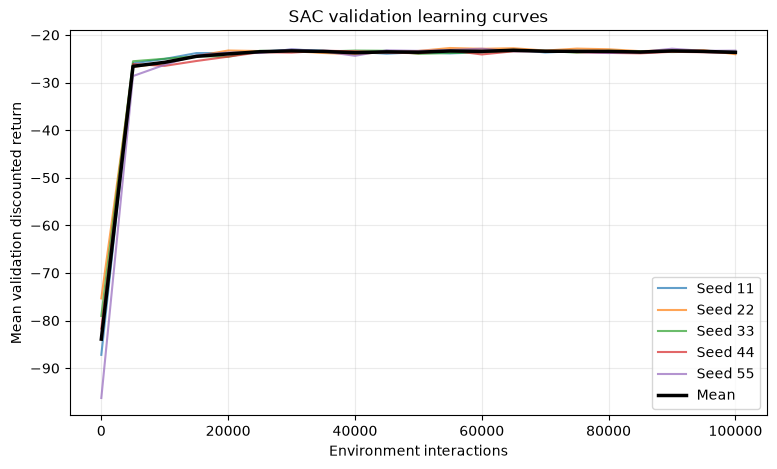

Available update-log columns: ['training_steps', 'q1_loss', 'q2_loss', 'value_loss', 'actor_loss', 'seed']


In [22]:
sac_eval_frames = []
sac_update_frames = []
for seed in SHARED_TRAINING["final_seeds"]:
    eval_path = final_dir / f"sac_final_seed{seed}_evaluations.csv"
    update_path = final_dir / f"sac_final_seed{seed}_updates.csv"
    for path in (eval_path, update_path):
        if not path.exists():
            raise FileNotFoundError(path)
    eval_frame = pd.read_csv(eval_path)
    eval_frame["seed"] = seed
    sac_eval_frames.append(eval_frame)
    update_frame = pd.read_csv(update_path)
    update_frame["seed"] = seed
    sac_update_frames.append(update_frame)
sac_final_evaluations = pd.concat(sac_eval_frames, ignore_index=True)
sac_final_updates = pd.concat(sac_update_frames, ignore_index=True)
validation = sac_final_evaluations.loc[sac_final_evaluations["split"] == "validation"]
curves = validation.groupby(["seed", "training_steps"], as_index=False)["discounted_return"].mean()
fig, ax = plt.subplots(figsize=(9, 5))
for seed, part in curves.groupby("seed"):
    ax.plot(part["training_steps"], part["discounted_return"], label=f"Seed {seed}", alpha=0.7)
mean_curve = curves.groupby("training_steps", as_index=False)["discounted_return"].mean()
ax.plot(mean_curve["training_steps"], mean_curve["discounted_return"], color="black", linewidth=2.5, label="Mean")
ax.set(xlabel="Environment interactions", ylabel="Mean validation discounted return", title="SAC validation learning curves")
ax.legend(); ax.grid(alpha=0.25); plt.show()
print("Available update-log columns:", sac_final_updates.columns.tolist())

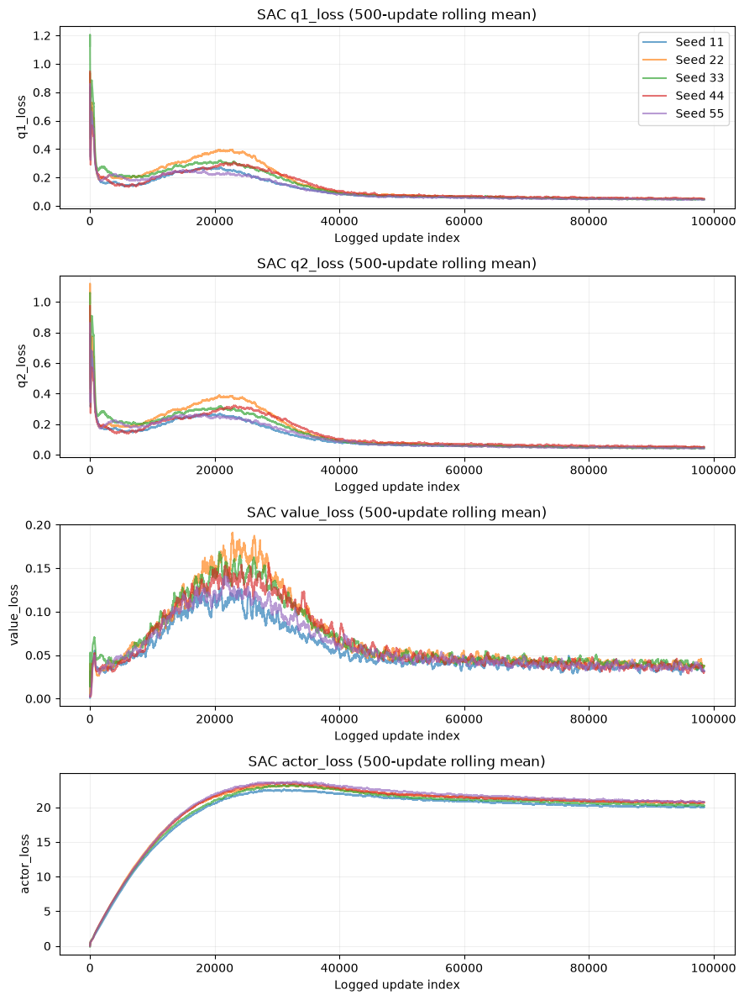

In [23]:
loss_cols = [c for c in sac_final_updates.columns if "loss" in c.lower()]
if not loss_cols:
    print("No loss columns found in saved update logs.")
else:
    fig, axes = plt.subplots(len(loss_cols), 1, figsize=(9, 3 * len(loss_cols)), squeeze=False)
    for ax, column in zip(axes[:, 0], loss_cols):
        for seed, part in sac_final_updates.groupby("seed"):
            # Rolling average smooths high-frequency per-update noise.
            values = pd.to_numeric(part[column], errors="coerce").reset_index(drop=True)
            ax.plot(values.rolling(500, min_periods=1).mean(), alpha=0.65, label=f"Seed {seed}")
        ax.set(xlabel="Logged update index", ylabel=column, title=f"SAC {column} (500-update rolling mean)")
        ax.grid(alpha=0.2)
    axes[0, 0].legend(); plt.tight_layout(); plt.show()

## 15. Reward sensitivity and robustness/generalisation

After configurations are frozen:

- train short reward-sensitivity runs with shortage weights 5 and 20 using seeds 101 and 202, then compare physical outcomes and nominally rescored returns;
- evaluate each final frozen policy without retraining on all four test seasons under nine one-at-a-time changes: $0.8C$, $1.2C$, 0.6 m root zone, efficiencies 0.75/0.95, planting ±14 days and $K_c$ ×0.9/×1.1; and
- retain the nominal 20 mm action limit and 150-day season.

These tests examine selected assumptions, not generalisation to every farm or climate. Capacity scenarios use known recalibration in the observation. Efficiency remains hidden from the RL policy. The changed $K_c$ is visible through the existing crop-coefficient observation.


In [24]:
def reward_sensitivity_plan():
    rows = []
    for agent_name in AGENT_TUNING_GRIDS:
        for scenario_name in REWARD_SENSITIVITY_CONFIGS:
            for seed in SHARED_TRAINING["tuning_seeds"]:
                rows.append({
                    "agent": agent_name, "scenario": scenario_name, "seed": seed,
                    "training_steps": SHARED_TRAINING["tuning_steps"],
                    "split": "train/validation only",
                })
    return pd.DataFrame(rows)


def evaluate_robustness(agent, agent_name, seed):
    rows = []
    for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
        scenario_results = evaluate_agent(
            agent, split="test", config=scenario_config,
            label=agent_name, seed=seed,
            training_steps=SHARED_TRAINING["final_checkpoint"],
        )
        scenario_results["scenario"] = scenario_name
        rows.append(scenario_results)
    return pd.concat(rows, ignore_index=True)


def evaluate_robustness_benchmark():
    rows = []
    for scenario_name, scenario_config in ROBUSTNESS_CONFIGS.items():
        # The threshold controller receives scenario capacity but retains its nominal 0.85 refill equation.
        results = evaluate_controller(
            lambda observation, capacity=scenario_config.capacity_mm: threshold_policy(observation, capacity),
            split="test", config=scenario_config, label="threshold",
            training_steps=0,
        )
        results["scenario"] = scenario_name
        rows.append(results)
    return pd.concat(rows, ignore_index=True)


print(reward_sensitivity_plan())


   agent            scenario  seed  training_steps                  split
0   ddpg   shortage_weight_5   101           30000  train/validation only
1   ddpg   shortage_weight_5   202           30000  train/validation only
2   ddpg  shortage_weight_20   101           30000  train/validation only
3   ddpg  shortage_weight_20   202           30000  train/validation only
4    td3   shortage_weight_5   101           30000  train/validation only
5    td3   shortage_weight_5   202           30000  train/validation only
6    td3  shortage_weight_20   101           30000  train/validation only
7    td3  shortage_weight_20   202           30000  train/validation only
8    sac   shortage_weight_5   101           30000  train/validation only
9    sac   shortage_weight_5   202           30000  train/validation only
10   sac  shortage_weight_20   101           30000  train/validation only
11   sac  shortage_weight_20   202           30000  train/validation only


### SAC — Reward Sensitivity and Robustness Experiments

The SAC reward-sensitivity experiments have been completed using shortage-penalty weights of 5 and 20, with two random seeds per configuration.

Robustness testing has also been completed across nine environmental scenarios, producing 180 evaluation records.

The results are saved under `outputs/sac/reward_sensitivity/` and `outputs/sac/robustness/`.

These experiments evaluate how SAC responds to changes in reward penalties and environmental conditions, separately from the nominal held-out test results.

In [25]:
for name, config in ROBUSTNESS_CONFIGS.items():
    print(name)

capacity_0.8
capacity_1.2
root_zone_0.6m
efficiency_0.75
efficiency_0.95
planting_minus_14d
planting_plus_14d
kc_0.9
kc_1.1


In [26]:
print("Robustness function ready:", callable(evaluate_robustness))

Robustness function ready: True


In [27]:
# Load the saved seed-11 SAC agent before robustness evaluation.
checkpoint = torch.load(
    final_dir / "sac_final_seed11.pt",
    map_location=DEVICE,
    weights_only=True
)

sac_replay_agent = SACAgent(
    observation_dim=18,
    action_dim=1,
    learning_rate=checkpoint["learning_rate"],
    alpha=checkpoint["alpha"]
)

sac_replay_agent.actor.load_state_dict(checkpoint["actor"])
sac_replay_agent.actor.eval()

sac_robustness_seed11 = evaluate_robustness(
    agent=sac_replay_agent,
    agent_name="sac",
    seed=11
)

display(sac_robustness_seed11.head())

,agent,seed,configuration,split,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm,status,scenario
0,sac,11,None,test,2021,100000,-21.946400,-32.254739,-32.254739,607.436069,0,0.000000,1.0,37.658701,ok,capacity_0.8
1,sac,11,None,test,2022,100000,-22.610086,-33.521961,-33.521961,629.012765,0,0.000000,1.0,41.426452,ok,capacity_0.8
2,sac,11,None,test,2023,100000,-24.394889,-36.383382,-36.383382,589.249190,1,0.649695,1.0,135.408348,ok,capacity_0.8
3,sac,11,None,test,2024,100000,-27.033385,-40.116623,-40.116623,745.958397,1,0.562923,1.0,53.535412,ok,capacity_0.8
4,sac,11,None,test,2021,100000,-20.453784,-30.162198,-30.162198,585.662399,0,0.000000,1.0,17.581567,ok,capacity_1.2


In [28]:
print("Total rows:", len(sac_robustness_seed11))

print("\nScenarios:")
print(sac_robustness_seed11["scenario"].value_counts())

print("\nStatuses:")
print(sac_robustness_seed11["status"].value_counts())

Total rows: 36

Scenarios:
scenario
capacity_0.8          4
capacity_1.2          4
root_zone_0.6m        4
efficiency_0.75       4
efficiency_0.95       4
planting_minus_14d    4
planting_plus_14d     4
kc_0.9                4
kc_1.1                4
Name: count, dtype: int64

Statuses:
status
ok    36
Name: count, dtype: int64


In [29]:
sac_robustness_seed11.to_csv(
    robustness_dir / "sac_robustness_seed11.csv",
    index=False
)

print("Seed 11 robustness results saved!")

Seed 11 robustness results saved!


In [30]:
for seed in [22, 33, 44, 55]:
    checkpoint = torch.load(
        final_dir / f"sac_final_seed{seed}.pt",
        map_location=DEVICE,
        weights_only=True
    )

    set_seed(seed)

    agent = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=checkpoint["learning_rate"],
        alpha=checkpoint["alpha"]
    )

    agent.actor.load_state_dict(checkpoint["actor"])
    agent.actor.eval()

    results = evaluate_robustness(
        agent=agent,
        agent_name="sac",
        seed=seed
    )

    if len(results) != 36 or not results["status"].eq("ok").all():
        raise ValueError(f"Robustness evaluation failed for seed {seed}")

    results.to_csv(
        robustness_dir / f"sac_robustness_seed{seed}.csv",
        index=False
    )

    print(f"Seed {seed}: {len(results)} evaluations saved successfully")

Seed 22: 36 evaluations saved successfully


Seed 33: 36 evaluations saved successfully


Seed 44: 36 evaluations saved successfully


Seed 55: 36 evaluations saved successfully


In [31]:
sac_robustness_all = pd.concat(
    [
        pd.read_csv(robustness_dir / f"sac_robustness_seed{seed}.csv")
        for seed in SHARED_TRAINING["final_seeds"]
    ],
    ignore_index=True
)

sac_robustness_all.to_csv(
    robustness_dir / "sac_robustness_all_seeds.csv",
    index=False
)

print("Total records:", len(sac_robustness_all))
print("Successful records:", sac_robustness_all["status"].eq("ok").sum())
print("Scenarios:", sac_robustness_all["scenario"].nunique())
print("Seeds:", sac_robustness_all["seed"].nunique())

Total records: 180
Successful records: 180
Scenarios: 9
Seeds: 5


In [32]:
sac_robustness_summary = (
    sac_robustness_all
    .groupby("scenario")[
        ["nominal_rescored_return", "irrigation_mm", "days_below_target"]
    ]
    .mean()
    .round(3)
)

display(sac_robustness_summary)

,nominal_rescored_return,irrigation_mm,days_below_target
scenario,,,
capacity_0.8,-35.762,640.764,1.30
capacity_1.2,-32.959,607.162,0.60
efficiency_0.75,-37.849,695.015,1.75
efficiency_0.95,-31.339,564.174,0.55
kc_0.9,-30.253,541.784,1.25
kc_1.1,-38.455,706.433,0.65
planting_minus_14d,-36.603,633.745,2.55
planting_plus_14d,-31.671,586.533,0.05
root_zone_0.6m,-37.453,659.476,1.50


In [33]:
sac_final_test = pd.read_csv(
    final_dir / "sac_final_test_all_seeds.csv"
)

print(sac_final_test.columns.tolist())

baseline = sac_final_test[
    ["seed", "season_year", "nominal_rescored_return"]
].rename(
    columns={"nominal_rescored_return": "baseline_return"}
)

sac_robustness_comparison = sac_robustness_all.merge(
    baseline,
    on=["seed", "season_year"],
    how="left",
    validate="many_to_one"
)

assert sac_robustness_comparison["baseline_return"].notna().all()

sac_robustness_comparison["return_change"] = (
    sac_robustness_comparison["nominal_rescored_return"]
    - sac_robustness_comparison["baseline_return"]
)

sac_robustness_changes = (
    sac_robustness_comparison
    .groupby("scenario")["return_change"]
    .agg(["mean", "std"])
    .round(3)
    .sort_values("mean")
)

display(sac_robustness_changes)

['agent', 'seed', 'configuration', 'split', 'season_year', 'training_steps', 'discounted_return', 'undiscounted_return', 'nominal_rescored_return', 'irrigation_mm', 'days_below_target', 'shortage_mm_days', 'actual_to_potential_et_ratio', 'drainage_mm', 'status']


,mean,std
scenario,,
kc_1.1,-4.344,0.593
efficiency_0.75,-3.738,0.781
root_zone_0.6m,-3.342,1.083
planting_minus_14d,-2.492,3.146
capacity_0.8,-1.651,0.526
capacity_1.2,1.152,0.437
planting_plus_14d,2.440,1.071
efficiency_0.95,2.772,0.538
kc_0.9,3.858,0.575


In [34]:
from dataclasses import replace

sac_reward_config_5 = replace(
    EnvironmentConfig(),
    shortage_weight=5.0
)

sac_reward_config_20 = replace(
    EnvironmentConfig(),
    shortage_weight=20.0
)

print("Scenario 1:", sac_reward_config_5.shortage_weight)
print("Scenario 2:", sac_reward_config_20.shortage_weight)

# Load completed experiments by default.
# Set to True only when intentionally repeating training.
RERUN_SAC_REWARD_TRAINING = False

def load_sac_reward_result(weight, seed):
    prefix = f"sac_reward_weight{weight}_seed{seed}"
    return {
        "evaluations": pd.read_csv(
            reward_dir / f"{prefix}_evaluations.csv"
        ),
        "updates": pd.read_csv(
            reward_dir / f"{prefix}_updates.csv"
        ),
    }

Scenario 1: 5.0
Scenario 2: 20.0


In [35]:
if RERUN_SAC_REWARD_TRAINING:
    set_seed(101)

    sac_reward_agent_5_101 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_5_101 = train_agent(
        agent=sac_reward_agent_5_101,
        seed=101,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_5
    )
else:
    sac_reward_result_5_101 = load_sac_reward_result(5, 101)

print("Reward weight 5, seed 101 results ready!")

Reward weight 5, seed 101 results ready!


In [36]:
sac_reward_eval_5_101 = sac_reward_result_5_101["evaluations"]

display(sac_reward_eval_5_101.tail())

print("Evaluation rows:", len(sac_reward_eval_5_101))
print("Statuses:")
print(sac_reward_eval_5_101["status"].value_counts())

,agent,seed,configuration,split,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm,status,runtime_seconds
23,sac,101,NaN,validation,2020,25000,-21.606769,-32.930386,-34.230942,612.913130,7,17.879237,1.0,19.683468,ok,78.502738
24,sac,101,NaN,validation,2017,30000,-24.972093,-37.238943,-38.020390,652.794969,3,11.709125,1.0,76.354954,ok,78.502738
25,sac,101,NaN,validation,2018,30000,-23.060315,-35.500220,-35.600362,708.001541,1,1.478941,1.0,0.000000,ok,78.502738
26,sac,101,NaN,validation,2019,30000,-23.668451,-35.314980,-35.653898,652.429042,2,5.037657,1.0,47.092218,ok,78.502738
27,sac,101,NaN,validation,2020,30000,-20.840297,-31.779592,-31.779592,614.086363,0,0.000000,1.0,21.505468,ok,78.502738


Evaluation rows: 28
Statuses:
status
ok    28
Name: count, dtype: int64


In [37]:
checkpoint_path = reward_dir / "sac_reward_weight5_seed101.pt"

if RERUN_SAC_REWARD_TRAINING:
    sac_reward_agent_5_101.save(checkpoint_path)
    print("Checkpoint saved:", checkpoint_path)
else:
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing saved SAC checkpoint: {checkpoint_path}"
        )
    print("Existing checkpoint verified:", checkpoint_path)

Existing checkpoint verified: /Users/zainumair12gmail.com/Desktop/comp6008-smart-irrigation-rl/outputs/sac/reward_sensitivity/sac_reward_weight5_seed101.pt


In [38]:
if RERUN_SAC_REWARD_TRAINING:
    set_seed(202)

    sac_reward_agent_5_202 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_5_202 = train_agent(
        agent=sac_reward_agent_5_202,
        seed=202,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_5
    )
else:
    sac_reward_result_5_202 = load_sac_reward_result(5, 202)

print("Reward weight 5, seed 202 results ready!")

Reward weight 5, seed 202 results ready!


In [39]:
evaluations = sac_reward_result_5_202["evaluations"]

print("Evaluation rows:", len(evaluations))
print("Statuses:")
print(evaluations["status"].value_counts())

assert len(evaluations) == 28
assert evaluations["status"].eq("ok").all()

checkpoint_path = reward_dir / "sac_reward_weight5_seed202.pt"

if RERUN_SAC_REWARD_TRAINING:
    sac_reward_agent_5_202.save(checkpoint_path)

    evaluations.to_csv(
        reward_dir / "sac_reward_weight5_seed202_evaluations.csv",
        index=False
    )

    sac_reward_result_5_202["updates"].to_csv(
        reward_dir / "sac_reward_weight5_seed202_updates.csv",
        index=False
    )

    print("Reward weight 5, seed 202 results saved!")
else:
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing saved SAC checkpoint: {checkpoint_path}"
        )

    print("Existing checkpoint and evaluation results verified!")

Evaluation rows: 28
Statuses:
status
ok    28
Name: count, dtype: int64
Existing checkpoint and evaluation results verified!


In [40]:
if RERUN_SAC_REWARD_TRAINING:
    set_seed(101)

    sac_reward_agent_20_101 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_20_101 = train_agent(
        agent=sac_reward_agent_20_101,
        seed=101,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_20
    )
else:
    sac_reward_result_20_101 = load_sac_reward_result(20, 101)

print("Reward weight 20, seed 101 results ready!")

Reward weight 20, seed 101 results ready!


In [41]:
evaluations = sac_reward_result_20_101["evaluations"]

print("Evaluation rows:", len(evaluations))
print("Statuses:")
print(evaluations["status"].value_counts())

assert len(evaluations) == 28
assert evaluations["status"].eq("ok").all()

checkpoint_path = reward_dir / "sac_reward_weight20_seed101.pt"

if RERUN_SAC_REWARD_TRAINING:
    sac_reward_agent_20_101.save(checkpoint_path)

    evaluations.to_csv(
        reward_dir / "sac_reward_weight20_seed101_evaluations.csv",
        index=False
    )

    sac_reward_result_20_101["updates"].to_csv(
        reward_dir / "sac_reward_weight20_seed101_updates.csv",
        index=False
    )

    print("Reward weight 20, seed 101 results saved!")
else:
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing saved SAC checkpoint: {checkpoint_path}"
        )

    print("Existing checkpoint and evaluation results verified!")

Evaluation rows: 28
Statuses:
status
ok    28
Name: count, dtype: int64
Existing checkpoint and evaluation results verified!


In [42]:
if RERUN_SAC_REWARD_TRAINING:
    set_seed(202)

    sac_reward_agent_20_202 = SACAgent(
        observation_dim=18,
        action_dim=1,
        learning_rate=0.0003,
        alpha=0.1
    )

    sac_reward_result_20_202 = train_agent(
        agent=sac_reward_agent_20_202,
        seed=202,
        total_steps=30000,
        agent_name="sac",
        config=sac_reward_config_20
    )
else:
    sac_reward_result_20_202 = load_sac_reward_result(20, 202)

print("Reward weight 20, seed 202 results ready!")

Reward weight 20, seed 202 results ready!


In [43]:
evaluations = sac_reward_result_20_202["evaluations"]

print("Evaluation rows:", len(evaluations))
print("Statuses:")
print(evaluations["status"].value_counts())

assert len(evaluations) == 28
assert evaluations["status"].eq("ok").all()

checkpoint_path = reward_dir / "sac_reward_weight20_seed202.pt"

if RERUN_SAC_REWARD_TRAINING:
    sac_reward_agent_20_202.save(checkpoint_path)

    evaluations.to_csv(
        reward_dir / "sac_reward_weight20_seed202_evaluations.csv",
        index=False
    )

    sac_reward_result_20_202["updates"].to_csv(
        reward_dir / "sac_reward_weight20_seed202_updates.csv",
        index=False
    )

    print("Reward weight 20, seed 202 results saved!")
else:
    if not checkpoint_path.exists():
        raise FileNotFoundError(
            f"Missing saved SAC checkpoint: {checkpoint_path}"
        )

    print("Existing checkpoint and evaluation results verified!")

Evaluation rows: 28
Statuses:
status
ok    28
Name: count, dtype: int64
Existing checkpoint and evaluation results verified!


In [44]:
import pandas as pd

reward_runs = [
    (5, 101, sac_reward_result_5_101),
    (5, 202, sac_reward_result_5_202),
    (20, 101, sac_reward_result_20_101),
    (20, 202, sac_reward_result_20_202),
]

reward_rows = []

for weight, seed, result in reward_runs:
    df = result["evaluations"]

    final_df = df[
        (df["training_steps"] == 30000)
        & (df["status"] == "ok")
    ].copy()

    final_df["shortage_weight"] = weight
    final_df["seed"] = seed

    reward_rows.append(final_df)

sac_reward_comparison = pd.concat(
    reward_rows, ignore_index=True
)

print("Final validation records:", len(sac_reward_comparison))

assert len(sac_reward_comparison) == 16

display(
    sac_reward_comparison.groupby("shortage_weight")[
        [
            "nominal_rescored_return",
            "irrigation_mm",
            "days_below_target",
        ]
    ].agg(["mean", "std"]).round(3)
)

Final validation records: 16


nominal_rescored_return         irrigation_mm          \
                                   mean     std          mean     std   
shortage_weight                                                         
5                               -39.764  10.049       643.164  37.285   
20                              -36.044   2.277       676.110  38.577   

                days_below_target          
                             mean     std  
shortage_weight                            
5                           7.875  10.371  
20                          0.000   0.000

In [45]:
sac_reward_comparison.to_csv(
    reward_dir / "sac_reward_sensitivity_all.csv",
    index=False
)

sac_reward_summary = (
    sac_reward_comparison
    .groupby("shortage_weight")[
        [
            "nominal_rescored_return",
            "irrigation_mm",
            "days_below_target",
        ]
    ]
    .agg(["mean", "std"])
)

sac_reward_summary.to_csv(
    reward_dir / "sac_reward_sensitivity_summary.csv"
)

print("Reward-sensitivity results saved successfully!")

Reward-sensitivity results saved successfully!


## 16. Failure analysis and debugging record

Do not attribute a failed run to an algorithm until the environment, reward, observations, exploration, gradients and numerical updates have been checked. Failed and unsuccessful runs remain part of the evidence.


In [46]:
FAILURE_COLUMNS = [
    "date", "agent", "configuration", "seed", "training_step", "observation",
    "suspected_cause", "evidence_checked", "change_made", "outcome",
    "resolved", "reviewer",
]
failure_log = pd.DataFrame(columns=FAILURE_COLUMNS)

INTEGRATION_CHECKLIST = pd.DataFrame([
    {"check": "Agent accepts 18-value float32 observation", "status": "TODO", "reviewer": None},
    {"check": "Training action is finite and bounded", "status": "TODO", "reviewer": None},
    {"check": "Terminal target has no bootstrap value", "status": "TODO", "reviewer": None},
    {"check": "External budget cut-off retains bootstrap", "status": "TODO", "reviewer": None},
    {"check": "Evaluation disables exploration/learning", "status": "TODO", "reviewer": None},
    {"check": "Weights, results and runtime persist outside memory", "status": "TODO", "reviewer": None},
    {"check": "Pseudocode maps to implementation", "status": "TODO", "reviewer": None},
])
INTEGRATION_CHECKLIST


,check,status,reviewer
0,Agent accepts 18-value float32 observation,TODO,None
1,Training action is finite and bounded,TODO,None
2,Terminal target has no bootstrap value,TODO,None
3,External budget cut-off retains bootstrap,TODO,None
4,Evaluation disables exploration/learning,TODO,None
5,"Weights, results and runtime persist outside m...",TODO,None
6,Pseudocode maps to implementation,TODO,None


In [47]:
import pandas as pd

# Load existing final SAC test results
sac_failure_data = pd.read_csv(
    final_dir / "sac_final_test_all_seeds.csv"
)

# Check the available columns
print("Available columns:")
print(sac_failure_data.columns.tolist())

print("\nTotal test records:", len(sac_failure_data))

# Show records with the most days below target
display(
    sac_failure_data.sort_values(
        "days_below_target",
        ascending=False
    ).head(10)
)

Available columns:
['agent', 'seed', 'configuration', 'split', 'season_year', 'training_steps', 'discounted_return', 'undiscounted_return', 'nominal_rescored_return', 'irrigation_mm', 'days_below_target', 'shortage_mm_days', 'actual_to_potential_et_ratio', 'drainage_mm', 'status']

Total test records: 20


,agent,seed,configuration,split,season_year,training_steps,discounted_return,undiscounted_return,nominal_rescored_return,irrigation_mm,days_below_target,shortage_mm_days,actual_to_potential_et_ratio,drainage_mm,status
6,sac,22,NaN,test,2023,100000,-22.691021,-34.760381,-34.760381,541.686049,6,12.842461,0.999971,103.998009,ok
7,sac,22,NaN,test,2024,100000,-27.647285,-42.023054,-42.023054,724.703726,6,16.901603,0.999829,47.409172,ok
10,sac,33,NaN,test,2023,100000,-23.209179,-34.703611,-34.703611,568.746165,1,0.269961,1.000000,124.325459,ok
3,sac,11,NaN,test,2024,100000,-26.291556,-39.069638,-39.069638,732.118921,1,0.134599,1.000000,48.730842,ok
17,sac,55,NaN,test,2022,100000,-20.984536,-31.569712,-31.569712,605.678876,1,1.000575,1.000000,22.880290,ok
5,sac,22,NaN,test,2022,100000,-21.080858,-31.672868,-31.672868,596.926923,1,4.646700,1.000000,23.364251,ok
15,sac,44,NaN,test,2024,100000,-26.504057,-39.423109,-39.423109,734.155474,1,1.233534,1.000000,49.330440,ok
12,sac,44,NaN,test,2021,100000,-20.748854,-30.525505,-30.525505,589.671513,0,0.000000,1.000000,20.838597,ok
18,sac,55,NaN,test,2023,100000,-22.630606,-34.051309,-34.051309,564.533963,0,0.000000,1.000000,116.492207,ok
16,sac,55,NaN,test,2021,100000,-20.193548,-29.982825,-29.982825,584.230511,0,0.000000,1.000000,15.425986,ok


In [48]:
sac_failure_cases = (
    sac_failure_data[
        sac_failure_data["days_below_target"] > 0
    ][
        [
            "seed",
            "season_year",
            "days_below_target",
            "shortage_mm_days",
            "irrigation_mm",
            "nominal_rescored_return",
        ]
    ]
    .sort_values(
        ["days_below_target", "shortage_mm_days"],
        ascending=False
    )
)

sac_failure_cases.to_csv(
    failure_dir / "sac_failure_cases.csv",
    index=False
)

print("Failure cases:", len(sac_failure_cases))
print("Maximum shortage days:", sac_failure_cases["days_below_target"].max())

display(sac_failure_cases)

Failure cases: 7
Maximum shortage days: 6


,seed,season_year,days_below_target,shortage_mm_days,irrigation_mm,nominal_rescored_return
7,22,2024,6,16.901603,724.703726,-42.023054
6,22,2023,6,12.842461,541.686049,-34.760381
5,22,2022,1,4.646700,596.926923,-31.672868
15,44,2024,1,1.233534,734.155474,-39.423109
17,55,2022,1,1.000575,605.678876,-31.569712
10,33,2023,1,0.269961,568.746165,-34.703611
3,11,2024,1,0.134599,732.118921,-39.069638


## 17. Results, interpretation and communication template

### Results to insert

1. Tuning table including failed trials and the selected configuration for each agent.
2. Validation learning curves against environment interactions, showing all seeds or uncertainty bands.
3. Final test results by season and by seed, plus five-seed mean and sample SD.
4. Physical trade-offs: irrigation, dry days, cumulative shortage, actual/potential ET and drainage.
5. Stability and sample-efficiency outcomes using the predeclared rules.
6. Nine robustness scenarios and reward-sensitivity results.
7. Agent-specific and end-to-end runtime measurements.

### Interpretation discipline

For every major conclusion, write:

- **Evidence:** the precise result or cited source.
- **Reasoning:** why it supports the conclusion.
- **Alternative explanation:** another plausible cause.
- **Assumptions and limits:** what was not established.

Do not call a noisy plateau convergence. Do not call lower irrigation an improvement if shortage rises materially. Held-out years at one location do not establish transfer to other farms. Simulated water status is not measured yield or plant health.

### Improvements and future extensions

| Member/agent | Demonstrated limitation | Evidence from results | Proposed improvement | Scientific source | Separate future direction |
|---|---|---|---|---|---|
| DDPG owner | TODO | TODO | TODO | TODO | TODO |
| TD3 owner | TODO | TODO | TODO | TODO | TODO |
| SAC owner | Performance varies under changed reward penalties and environmental conditions; results are limited to the simulated environment | Reward-sensitivity experiments across two penalty weights and nine robustness scenarios (180 evaluation records) | Investigate more robust reward design and evaluate performance across additional weather conditions | Liu et al. (2025), *Deep Reinforcement Learning for irrigation optimization: Advantages, opportunities, and challenges*, *Agricultural Water Management*, 322, 110030. https://doi.org/10.1016/j.agwat.2025.110030 | Evaluate transfer to another irrigation location and incorporate more realistic field constraints |


In [49]:
# Load saved CSV/JSON result files here; do not rely only on notebook memory.
all_results = pd.DataFrame(columns=RESULT_COLUMNS)

# Required figures after runs exist:
# 1. Mean validation return versus environment interactions, with seed variation.
# 2. Test irrigation versus shortage trade-off.
# 3. Test metrics by agent and season.
# 4. Robustness metric changes relative to the nominal scenario.


In [50]:
import pandas as pd

sac_test = pd.read_csv(
    final_dir / "sac_final_test_all_seeds.csv"
)

# Average the four test seasons for each seed
sac_seed_summary = (
    sac_test.groupby("seed")[
        [
            "discounted_return",
            "irrigation_mm",
            "days_below_target",
        ]
    ]
    .mean()
)

# Calculate mean and standard deviation across five seeds
sac_results_summary = (
    sac_seed_summary.agg(["mean", "std"]).round(3)
)

display(sac_results_summary)

sac_results_summary.to_csv(
    final_dir / "sac_results_summary.csv"
)

print("Final SAC results summary saved successfully!")

,discounted_return,irrigation_mm,days_below_target
mean,-22.847,621.808,0.850
std,0.359,6.795,1.342


Final SAC results summary saved successfully!


### SAC — held-out test results and farm replay

The cells below read existing files and replay a trained deterministic policy. No optimisation occurs.

In [51]:
checkpoint_path = final_dir / "sac_final_seed11.pt"

print("Checkpoint exists:", checkpoint_path.exists())
print("Checkpoint path:", checkpoint_path)

Checkpoint exists: True
Checkpoint path: /Users/zainumair12gmail.com/Desktop/comp6008-smart-irrigation-rl/outputs/sac/final/sac_final_seed11.pt


In [52]:
checkpoint = torch.load(
    checkpoint_path,
    map_location=DEVICE,
    weights_only=True
)

sac_replay_agent = SACAgent(
    observation_dim=18,
    action_dim=1,
    learning_rate=checkpoint["learning_rate"],
    alpha=checkpoint["alpha"]
)

sac_replay_agent.actor.load_state_dict(checkpoint["actor"])
sac_replay_agent.actor.eval()

print("SAC checkpoint loaded successfully!")

SAC checkpoint loaded successfully!


In [53]:
sac_test_frames = []
for seed in SHARED_TRAINING["final_seeds"]:
    path = final_dir / f"sac_final_seed{seed}_test.csv"
    if not path.exists():
        raise FileNotFoundError(path)
    frame = pd.read_csv(path)
    frame["seed"] = seed
    sac_test_frames.append(frame)
sac_final_test = pd.concat(sac_test_frames, ignore_index=True)
sac_seed_means = sac_final_test.groupby("seed")[["discounted_return", "irrigation_mm", "days_below_target"]].mean()
sac_summary = pd.DataFrame({"mean": sac_seed_means.mean(), "std_across_seeds": sac_seed_means.std(ddof=1)})
display(sac_summary)

,mean,std_across_seeds
discounted_return,-22.846902,0.359483
irrigation_mm,621.807842,6.795192
days_below_target,0.850000,1.341641


In [54]:
# SAC deterministic replay of one validation season; no training or checkpoint writes.
replay_seed = 11
checkpoint_path = final_dir / f"sac_final_seed{replay_seed}.pt"
if not checkpoint_path.exists():
    raise FileNotFoundError(checkpoint_path)
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
sac_replay_agent = SACAgent(
    observation_dim=18, action_dim=1,
    learning_rate=checkpoint["learning_rate"], alpha=checkpoint["alpha"]
)
sac_replay_agent.actor.load_state_dict(checkpoint["actor"])
sac_replay_agent.actor.eval()
def sac_replay_policy(observation):
    return sac_replay_agent.select_action(observation, evaluate=True)
sac_playback, sac_replay_daily = visualise_season(
    sac_replay_policy, label=f"SAC seed {replay_seed}", split="validation", season_year=2017
)
display(sac_playback)

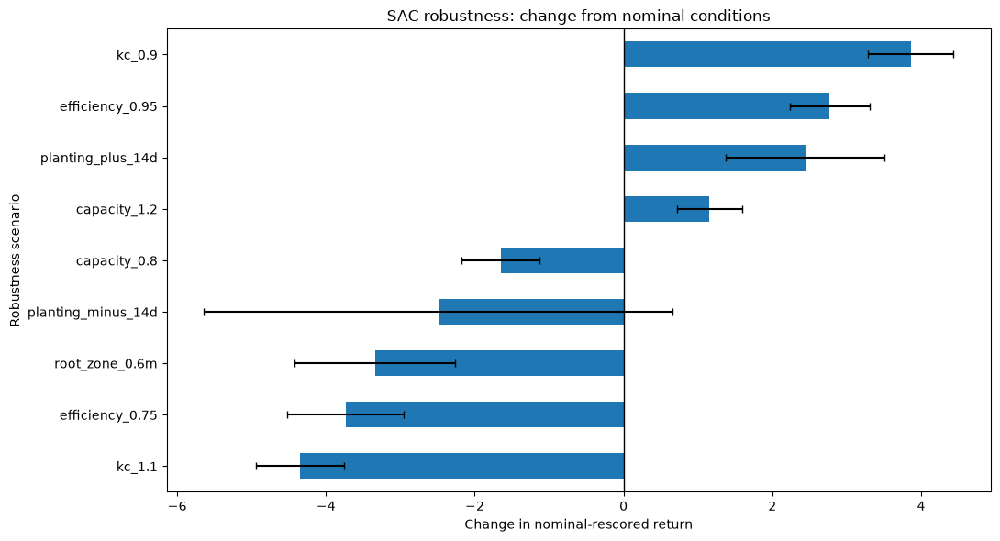

In [55]:
fig, ax = plt.subplots(figsize=(11, 6))

sac_robustness_changes["mean"].plot(
    kind="barh",
    xerr=sac_robustness_changes["std"],
    ax=ax,
    capsize=3
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title("SAC robustness: change from nominal conditions")
ax.set_xlabel("Change in nominal-rescored return")
ax.set_ylabel("Robustness scenario")

plt.tight_layout()

fig.savefig(
    robustness_dir / "sac_robustness_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 18. Feasibility and milestone record

The environment is feasible because it uses in-memory arrays and explicit arithmetic; no paid service, crop-growth package, solver or live hardware is required. This does not guarantee that every neural agent will train successfully.

| Date | Milestone | Completion evidence | Status |
|---|---|---|---|
| 5–6 October | Data, settings and shared environment | Complete seasons, fixed interface and configuration fingerprint | Complete |
| 6–7 October | Physics and information-timing validation | Controlled cases, mass balance, reproducibility and terminal checks | Complete in template; peer review TODO |
| 7 October | Agent integration and environment timing | Three smoke runs plus active-runtime timing | TODO |
| 7–8 October | Independent environment review | Equations/code/settings checked by another member | TODO |
| 11 October | Agent implementations and runtime pilots | DDPG, TD3 and SAC integrated; 10,000-step timings | TODO |
| 15 October | Tuning | All declared configurations, seeds and failures recorded | TODO |
| 18 October | Final experiments | Five-seed tests, reward sensitivity and robustness saved | TODO |
| 19–22 October | Analysis and presentation | Reproducible figures/tables and recorded presentation | TODO |
| 29 October | Report review | Group review before 30 October deadline | TODO |

If runtime becomes restrictive, first reduce avoidable I/O and logging. Any budget change must be documented and applied equally before final testing; test performance cannot be used to give a preferred agent extra tuning.


### SAC Feasibility Discussion

Soft Actor-Critic (SAC) was implemented to learn continuous
daily irrigation decisions in the Kyabram maize irrigation
environment.

The agent was trained using five random seeds, with
100,000 environment steps per seed.

**Predictive performance and water management**

Across the held-out test seasons (2021–2024), SAC achieved:

- Mean discounted return: -22.847 ± 0.359
- Mean seasonal irrigation: 621.808 ± 6.795 mm
- Mean days below the soil-moisture target: 0.850 ± 1.342

The results indicate that SAC can learn irrigation policies
that generally maintain soil moisture near the target while
controlling irrigation quantities in the simulated environment.

**Robustness**

SAC was evaluated under nine environmental perturbations,
including changes to irrigation efficiency, soil-water
capacity, rooting depth, planting date and crop coefficients.

All 180 robustness evaluations completed successfully.
However, performance declined under some perturbations,
particularly increased crop water demand and reduced
irrigation efficiency.

**Reward sensitivity**

Increasing the soil-moisture shortage penalty from 5 to 20
reduced the average number of days below target from
7.875 to 0 across the validation experiments, while
increasing mean seasonal irrigation from approximately
643 mm to 676 mm.

This demonstrates a trade-off between conserving irrigation
water and preventing soil-moisture shortages.

**Limitations**

The evaluation uses a simulated irrigation environment
rather than real-world farm deployment. Results may depend
on assumptions about soil properties, irrigation efficiency,
crop water demand and weather conditions.

Some trained policies experienced soil-moisture shortages,
indicating sensitivity to random seeds and seasonal conditions.

**Conclusion**

SAC is a feasible candidate for continuous irrigation control
within the simulated environment. Further comparison with
other reinforcement learning agents and validation against
real-world agricultural data would be required before
considering practical deployment.

## 19. References

[1] R. S. Sutton and A. G. Barto, *Reinforcement Learning: An Introduction*, 2nd ed., MIT Press, 2018, ISBN 9780262039246.

[2] R. G. Allen, L. S. Pereira, D. Raes, and M. Smith, *Crop Evapotranspiration: Guidelines for Computing Crop Water Requirements*, FAO Irrigation and Drainage Paper 56, 1998.

[3] K. L. Greenwood, A. R. Lawson, and K. B. Kelly, “The water balance of irrigated forages in northern Victoria, Australia,” *Agricultural Water Management*, 96(5), 847–858, 2009. https://doi.org/10.1016/j.agwat.2008.11.005

[4] T. P. Lillicrap et al., “Continuous control with deep reinforcement learning,” *ICLR*, 2016. https://arxiv.org/abs/1509.02971

[5] S. Fujimoto, H. van Hoof, and D. Meger, “Addressing function approximation error in actor-critic methods,” *ICML/PMLR 80*, 1587–1596, 2018. https://proceedings.mlr.press/v80/fujimoto18a.html

[6] T. Haarnoja, A. Zhou, P. Abbeel, and S. Levine, “Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor,” *ICML/PMLR 80*, 1861–1870, 2018. https://proceedings.mlr.press/v80/haarnoja18b.html

[7] P. Henderson et al., “Deep reinforcement learning that matters,” *AAAI*, 32(1), 2018. https://doi.org/10.1609/aaai.v32i1.11694

[8] S. J. Jeffrey et al., “Using spatial interpolation to construct a comprehensive archive of Australian climate data,” *Environmental Modelling & Software*, 16(4), 309–330, 2001. https://doi.org/10.1016/S1364-8152(01)00008-1

[9] K. L. Greenwood, G. N. Mundy, and K. B. Kelly, “On-farm measurement of the water use and productivity of maize,” *Australian Journal of Experimental Agriculture*, 48(3), 274–284, 2008. https://doi.org/10.1071/EA06094

[10] L. S. Pereira et al., “Standard single and basal crop coefficients for field crops,” *Agricultural Water Management*, 243, 106466, 2021. https://doi.org/10.1016/j.agwat.2020.106466

[11] B. P. Malone et al., “Update and expansion of the soil and landscape grid of Australia,” *Geoderma*, 455, 117226, 2025. https://doi.org/10.1016/j.geoderma.2025.117226

[12] R. Searle, P. D. S. N. Somarathna, and B. Malone, *Soil and Landscape Grid National Soil Attribute Maps – Available Volumetric Water Capacity*, CSIRO dataset, 2022. https://doi.org/10.25919/4jwj-na34

Publication status, DOI checks and claim limits are documented in [`PROJECT_OBJECTIVES.md`](../docs/PROJECT_OBJECTIVES.md). The textbook, FAO manual and dataset are authoritative or provenance sources rather than peer-reviewed journal papers; the original algorithm papers are peer-reviewed conference papers without identified conference DOIs.


## 20. Final reproducibility checklist

- [ ] All three agents use this environment and the same saved configuration fingerprint.
- [ ] Environment validation passes on the final runtime and receives independent review.
- [ ] Practical reuse and every algorithm's pseudocode-to-code mapping are documented.
- [ ] Agent-specific `None` values are filled from validation tuning only.
- [ ] All tuning configurations and failed runs are retained.
- [ ] Test seasons are untouched until environment, reward, settings and selection are frozen.
- [ ] All five final seeds use 100,000 interactions and the same season schedule per seed.
- [ ] Step-zero and 5,000-step validation evaluations contain no learning or replay insertion.
- [ ] True terminal transitions do not bootstrap; external cut-offs do.
- [ ] Step 100,000—not a favourable intermediate checkpoint—is used for final tests.
- [ ] Seed-level and season-level results, sample SD, learning curves and physical metrics are reported.
- [ ] Stability and sample efficiency use the declared operational definitions.
- [ ] Reward-sensitivity and all nine one-at-a-time robustness scenarios are completed without test-driven redesign.
- [ ] Weights, CSV/JSON results, package versions, hardware and runtimes are saved persistently.
- [ ] Conclusions separate evidence, reasoning, alternatives and limitations.
- [ ] Every member can explain the environment and all three agents.
